# 05 NLP pipeline

Geo-sentence classification, indicators, novelty measures and the LLM validation sample. Lexicons in cell 3 (exported to `data/lexicons/`). Outputs: `data/features/nlp_features.parquet`, `data/features/novelty_placebo.csv`, `output/validation/v2/`. Produces Tables 4 and 5, Appendix Table III.1 and Appendices VIII and IX.

In [2]:
from __future__ import annotations

import json
import re
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Optional visualisation
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    _HAS_PLOT = True
except ImportError:
    _HAS_PLOT = False

# Optional NER — used by compute_specificity()
try:
    import spacy
    _HAS_SPACY = True
except ImportError:
    _HAS_SPACY = False
    warnings.warn(
        "spaCy not found — Specificity will use channel terms only (no NER).\n"
        "To enable NER: pip install spacy && python -m spacy download en_core_web_sm",
        stacklevel=2,
    )

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import subprocess, sys
def _spacy_model_installed(name):
    try:
        import spacy; spacy.load(name); return True
    except (ImportError, OSError):
        return False

for _model in ["en_core_web_trf", "en_core_web_lg"]:
    if not _spacy_model_installed(_model):
        print(f"Downloading {_model} ...")
        subprocess.run([sys.executable, "-m", "spacy", "download", _model], check=False)
    else:
        print(f"{_model} already installed.")
        break


en_core_web_trf already installed.


In [3]:
# ── Paths ─────────────────────────────────────────────────────────────────
DATA_DIR    = Path("../data/processed")
OUT_DIR     = Path("../data/features")
OUT_PARQUET = "../data//features/nlp_features.parquet"
OUT_CSV     = "../data//features/nlp_features.csv"

# ── TF-IDF parameters (Boilerplate / Novelty) ─────────────────────────────
TFIDF_MAX_FEATURES = 20_000
TFIDF_NGRAM_RANGE  = (1, 2)

# ── Minimum geo content thresholds ────────────────────────────────────────
MIN_GEO_SENTS  = 3    # minimum geo sentences
MIN_GEO_TOKENS = 100  # minimum geo tokens     (guards specificity ratio)

# ===========================================================================
# GPR DICTIONARY
# Caldara & Iacoviello (2022, AER) five-category taxonomy extended for 10-K.
# Academic basis: C&I (2022); Allison (2017); Drezner (1999); Kobrin (1979);
#                 Henisz (2000); Buzan et al. (1998); Loughran & McDonald (2011)
# ===========================================================================

# ── Category 1: Armed Conflict & Terrorism ──────────────────────────────────
CAT1_CONFLICT_TERRORISM = [
    "armed conflict", "military conflict", "military action",
    "military operation", "military force", "military buildup",
    "military escalat", "combat operation",
    "war ",            # compiled as r"\bwar\b" — see _WORD_BOUNDARY_OVERRIDES
    "warfare", "wartime", "civil war",
    "insurgency", "insurgent", "paramilitary",
    "invasion", "invasion of", "occupied territory", "occupation",
    "airstrike", "air strike", "drone strike",
    "missile strike", "missile attack", "bombing", "shelling",
    "nuclear threat", "nuclear weapon", "nuclear program", "nuclear proliferat",
    "weapons of mass destruction", "chemical weapon", "biological weapon",
    "terrorism", "terrorist", "terror attack",
    "extremist", "extremism", "jihadist",
    "militant group", "militant attack", "suicide bombing",
    "ceasefire violation", "peace negotiat", "peace process",
    "armed faction", "armed group", "belligerent", "belligerency",
]

# ── Category 2: Interstate Tensions & Great-Power Competition ───────────────
CAT2_GEOPOLITICAL_TENSIONS = [
    "geopolit", "interstate tension", "bilateral tension",
    "diplomatic tension", "diplomatic conflict", "diplomatic incident",
    "diplomatic relation", "deteriorat", "escalat",
    "stand-off", "standoff", "brinkmanship", "provocation",
    "great power competition", "great-power competition", "strategic competition",
    "hegemonic", "superpower",
    "decoupling", "technological decoupling", "economic decoupling",
    "deglobalization", "deglobalisation", "fragmentation of",
    "geoeconomic", "geostrateg",
    "supply chain disruption", "supply disruption",
    "supply chain securit", "supply chain resilience", "supply chain risk",
    "reshoring", "nearshoring", "friend-shoring", "friendshoring", "onshoring",
    "critical supply", "strategic supply",
    # Standalone high-signal flashpoints (no proximity needed) 
    "taiwan strait", "south china sea", "ukraine war", "russia-ukraine",
    "ukraine conflict", "nato alliance", "nato member", "transatlantic",
]

# ── Category 3: Economic Sanctions & Trade Restrictions ─────────────────────
CAT3_SANCTIONS_TRADE = [
    "sanction", "ofac", "sdn list", "specially designated",
    "blocked person", "blocked entity",
    "secondary sanction", "sectoral sanction", "financial sanction",
    "targeted sanction", "counter-sanction", "countersanction",
    "asset freeze", "asset seizure", "frozen asset", "embargo",
    "itar",
    "ear ",   # compiled as r"\bear\b" (Export Administration Regulations)
    "cfius",
    "bis ",   # compiled as r"\bbis\b" (Bureau of Industry and Security)
    "export control", "export license", "export restriction",
    "import restriction", "import tariff",
    "denied party", "entity list", "restricted party list",
    "debarment", "debarred", "dual-use",
    "munitions list", "commerce control list",
    "trade war", "trade barrier", "trade restriction", "trade sanction",
    "trade tension", "tariff", "retaliatory tariff",
    "countervailing duty", "anti-dumping", "antidumping",
    "most favored nation", "mfn status", "trade agreement", "wto dispute",
    "market access restriction", "investment restriction", "investment control",
    "foreign investment review", "forced technology transfer", "technology ban",
]

# ── Category 4: Political Instability & Regime Risk ─────────────────────────
CAT4_REGIME_POLITICAL = [
    "political risk", "political instability", "political uncertainty",
    "political turmoil", "political violence", "political crisis",
    "political transition", "regime change", "regime instability",
    "coup", "coup d'etat", "government overthrow", "government collapse",
    "civil unrest", "civil disturbance", "social unrest", "riot",
    "civil protest", "protest movement", "general strike", "popular uprising",
    "revolution", "separatist", "secessionist",
    "ethnic conflict", "sectarian conflict", "sectarian violence", "communal violence",
    "nationalization", "nationalisation", "expropriation",
    "nationalized", "nationalised", "confiscation", "expropriated",
    "seizure of assets", "asset confiscation", "forced divestiture",
    "forced sale", "sovereign seizure",
    "sovereign risk", "sovereign default", "sovereign debt", "country risk",
    "government stability", "institutional stability", "rule of law",
    "corruption risk", "bribery risk", "anti-bribery",
    "fcpa", "foreign corrupt practices",
    "martial law", "state of emergency", "emergency powers",
]

# ── Category 5: Regulatory Sovereignty & Technology Risk ────────────────────
CAT5_REGULATORY_SOVEREIGNTY = [
    "data localiz", "data localis", "data sovereignty", "data residency",
    "cross-border data", "data transfer restrict", "personal data transfer",
    "gdpr", "schrems", "standard contractual clause",
    "technology restriction", "technology transfer", "technology decoupling",
    "technology ban", "technology competition",
    "critical technology", "emerging technology", "advanced technology",
    "semiconductor", "semiconductor export", "chip restriction",
    "quantum", "artificial intelligence restriction", "ai restriction", "ai export",
    "foreign ownership restriction", "foreign ownership limit",
    "local content requirement", "local manufacturing requirement",
    "indigenization", "local partner requirement",
    "joint venture requirement", "forced joint venture",
    "investment screening",
    "national security review", "national security concern", "national security risk",
    "critical infrastructure", "critical sector", "strategic sector", "sensitive sector",
    "government-directed", "state-directed", "state-owned enterprise",
    "soe",
        # ── 5a. Semiconductor & Hardware Controls ────────────────────────────────
    # Semiconductor export controls (CHIPS Act, BIS rules on advanced chips)
    "chips and science act",
    "advanced node",
    "logic chip",
    "high bandwidth memory",
    "hbm",              # compile as r"\bhbm\b" — low false positive in 10-K context
    "a100", "h100",      # NVIDIA chip model names subject to export controls
    "advanced computing",
    "supercomputing",
    "foundry",            # semiconductor foundry — context-dependent; retain proximity req
    "wafer",              # retain proximity requirement to avoid false positives
    "equipment restriction",
    "lithography",
    "asml",              # company name but near-uniquely GPR-relevant in 10-K context
    "dutch export",

    # ── 5b. AI & Emerging Technology Governance ──────────────────────────────
    # AI-specific export controls and sovereignty regulation (2023-2025)
    "ai governance",
    "ai regulation",
    "foundation model",
    "frontier model",
    "large language model",
    "generative ai",      # retain proximity requirement
    "algorithmic sovereignty",
    "eu ai act",
    "ai liability",
    "biometric",          # biometric data regulation — retain proximity requirement
    "quantum computing",  # more specific than bare "quantum"
    "quantum encryption",
    "post-quantum",

    # ── 5c. Data Governance & Digital Sovereignty ────────────────────────────
    # Non-EU data sovereignty laws (China PIPL, India DPDP, etc.)
    "data protection law",
    "data protection regulation",
    "personal information protection",  # China PIPL
    "pipl",               # compile as r"\bpipl\b"
    "digital personal data",             # India DPDP Act
    "dpdp",               # compile as r"\bdpdp\b"
    "cloud sovereignty",
    "digital sovereignty",
    "government access",  # retain proximity requirement
    "lawful access",
    "surveillance law",
    "network security law",              # China Cybersecurity Law
    "cybersecurity law",  # retain proximity req — "cybersecurity" alone is Cat-1 adjacent
    "foreign cloud",
    "strategic cloud",

    # ── 5d. Investment Screening & Ownership Controls ────────────────────────
    # Allied-country investment screening regimes (post-2020)
    "national security and investment",  # UK NSI Act
    "nsi act",
    "foreign investment security",
    "golden share",
    "special share",
    "mandatory notification",            # retain proximity requirement
    "call-in power",
    "foreign subsidies regulation",      # EU FSR
    "fsr",                # compile as r"\bfsr\b" — moderate false positive risk
    "outbound investment",               # US outbound investment rules (EO 14105)
    "outbound capital",
    "covered transaction",               # CFIUS statutory term

    # ── 5e. Supply Chain Traceability & Forced Labour ────────────────────────
    # Uyghur Forced Labor Prevention Act (UFLPA) and analogous rules (post-2022)
    "uflpa",
    "uyghur forced labor",
    "forced labor",       # retain proximity requirement — standalone too broad
    "supply chain due diligence",
    "supply chain transparency",
    "deforestation regulation",          # EU EUDR — Cat-5 adjacent
    "conflict mineral",
    "xinjiang",           # compile with proximity requirement
]   # compiled as r"\bsoe\b" — only meaningful in political/regulatory context


# ── High-Precision Channel Terms ─────────────────────────────────────────────
# Match standalone — no proximity needed. Rarely appear outside GPR context in 10-Ks.
CHANNEL_TERMS = [
    "ofac", "sdn list", "specially designated national",
    "itar",
    r"\bear\b",   # Export Administration Regulations (regex — avoids "early", "earn")
    "cfius",
    r"\bbis\b",   # Bureau of Industry and Security  (regex — avoids common words)
    "export administration regulation", "international traffic in arms",
    "commerce control list", "munitions list",
    "entity list", "denied party", "debarred", "debarment",
    "iran nuclear deal", "jcpoa",
    "swift exclusion", "swift ban",
    "ofac license", "general license", "specific license",
    "blocked person", "blocked entity",
    "foreign direct product rule", "fdpr",
    "chip act", "chips act",
    "section 232", "section 301", "section 721",
    "executive order 13959", "executive order 14032",
    "uflpa",
    "pipl",               # r"\bpipl\b"
    "chips act",
    "section 889",        # NDAA telecom ban (Huawei/ZTE)
    "section 1260h",      # Chinese military company designation
    "executive order 14105",  # outbound investment EO
    "national security memorandum",
    "eu ai act",
    "foreign subsidies regulation",
]

# ── Country / Region Proximity Terms ─────────────────────────────────────────
# These are NOT flagged standalone. is_gpr_sentence() flags them only when
# a SEED or GEO_NEGATIVE term appears within ±15 tokens.
COUNTRY_PROXIMITY = [
    "russia", "ukraine", "china", "taiwan", "iran", "north korea", "dprk",
    "israel", "gaza", "west bank", "middle east", "red sea", "persian gulf",
    "straits of hormuz", "south china sea",
    "venezuela", "myanmar", "belarus", "cuba", "syria", "sudan",
    "mali", "yemen", "afghanistan", "pakistan", "ethiopia", "haiti",
    "xinjiang",
    "hong kong",         # already implicit via China; flag explicitly for NHK-related rules
    "huawei",
    "zte",               # r"\bzte\b"
    "tiktok",
    "bytedance",
    "smic",
]

# ── Modifier Lists (applied on top of GPR-flagged sentences) ─────────────────
GEO_NEGATIVE = [
    "threat", "hostile", "hostility", "aggression", "aggressive",
    "coercive", "coercion", "destabiliz", "destabilis", "deteriorat",
    "escalat", "heightened", "intensif",
    "disrupt", "disruption", "disrupted",
    "impair", "impairment",
    "adverse", "adversely", "adversely affect", "negatively affect",
    "harm", "damage", "injure", "jeopardize", "jeopardise",
    "undermine", "curtail", "restrict", "restriction", "constrain", "preclude",
    "volatil", "instability", "uncertainty",
    "unfavorable", "unfavourable",
    "penalty", "fine", "loss", "losses", "write-down", "write-off",
    "impede", "stall", "suspend", "halt", "cease", "exit", "withdraw", "divest",
    "sanction", "seizure", "confiscation", "liabilit",
    "enforcement action", "legal challenge", "dispute", "prosecution",
]

LM_UNCERTAINTY = [
    # ── Epistemic state terms ────────────────────────────────────────────────
    "uncertain", "uncertainty", "unclear",
    "ambiguous", "ambiguity",
    "unpredictable", "unpredictability",
    "unforeseeable", "unforeseen",
    "approximat",
    "contingent", "contingency", "contingencies",

    # ── Epistemic modals (not in FORWARD_LOOKING) ───
    "may ",    # compiled as r"\bmay\b"
    "might ",  # compiled as r"\bmight\b"
    "could ",  # compiled as r"\bcould\b"
    "would ",  # compiled as r"\bwould\b"
    "possibly", "potentially", "perhaps",
    "likelihood", "probable", "improbable",

    # ── Hedged propositional constructions ───────────────────────────────────
    "risk that", "risk of",
    "possibility that", "possibility of",
    "exposure to", "subject to",
    "dependent on", "susceptible to",
    "we cannot assure", "we cannot guarantee",
    "no assurance", "no guarantee",
    "cannot predict", "difficult to predict",
    "difficult to assess", "hard to predict",
    "we do not know",
    "we are unable to predict", "we are unable to foresee",
]

FORWARD_LOOKING = [
    # ── Explicit intent markers (company as agent) ───────────────────────────
    "we will ",        # compiled as r"\bwe will\b" — clear prospective intent
    "we plan to",
    "we intend to",
    "we expect to",     # "expect" = forward-looking intent, not epistemic hedge
    "we expect that",
    "we anticipate",
    "we aim to",
    "we seek to",
    "we continue to",
    "we pursue",
    "we have implemented",
    "we are implementing",
    "we are developing",
    "we are evaluating",
    "we are monitoring",
    "we are assessing",
    "we are working to",
    "we are taking steps",
    "we have taken steps",
    "we have adopted",
    "we are prepared",

    # ── Prospective temporal markers ─────────────────────────────────────────
    "in the future",
    "in future periods",
    "in coming year",
    "in the coming year",
    "in subsequent period",
    "going forward",
    "over the next",
    "in the next",
    "during the next",
    "future period",
    "future development",
    "future impact",
    "future event",
    "prospective",

    # ── Conditional prospective constructions ────────────────────────────────
    "if enacted",
    "if implemented",
    "if imposed",
    "if escalated",
    "should these",
    "were these to",
    "in the event of",
    "in the event that",
    "in the event such",
]

MITIGATIVE = [
    "mitigat", "hedge", "hedging", "diversif",
    "contingency plan", "contingency measure",
    "business continuity", "continuity plan",
    "resilien", "adapt", "adaptation",
    "monitor", "monitoring",
    "compliance program", "compliance framework", "comply",
    "alternative supplier", "alternative source", "backup supplier",
    "redundan", "flexib",
    "minimize", "minimise", "offset",
    "insurance", "insured", "protect", "safeguard", "countermeasure",
    "risk management", "risk mitigation", "de-risk", "derisk",
    "scenario planning", "stress test", "buffer", "reserve",
]

REMOVE_SEED = {
    "deteriorat", "escalat",                                    # credit quality, cost escalation
    "supply chain disruption", "supply disruption", "supply chain risk",
    "supply chain resilience", "critical supply", "strategic supply", "fragmentation of",
    "fcpa", "foreign corrupt practices", "anti-bribery", "bribery risk", "corruption risk",
    "semiconductor", "foundry", "wafer", "quantum", "advanced technology",
    "emerging technology", "critical technology", "advanced computing", "supercomputing",
    "generative ai", "large language model", "foundation model", "frontier model",
    "ai governance", "ai regulation", "ai liability", "biometric",
    "gdpr", "data protection law", "data protection regulation", "personal data transfer",
    "standard contractual clause", "schrems",
    "conflict mineral", "forced labor", "deforestation regulation",
    "supply chain due diligence", "supply chain transparency", "debarment", "debarred",
    "critical infrastructure", "critical sector", "strategic sector", "sensitive sector",
    "mandatory notification", "government access", "sanction", "decoupling"
}

for _lst in (CAT2_GEOPOLITICAL_TENSIONS, CAT3_SANCTIONS_TRADE, CAT4_REGIME_POLITICAL,
             CAT5_REGULATORY_SOVEREIGNTY, CHANNEL_TERMS):
    _lst[:] = [t for t in _lst if t not in REMOVE_SEED]   # in place, so GPR_CATEGORIES follows

# Geopolitical sanctions only. "sanction" stays in GEO_NEGATIVE, so sentences with
# "sanctions" near a country name (e.g. Russia) are still flagged by the proximity rule.
CAT3_SANCTIONS_TRADE.append(
    r"\b(economic|trade|financial|international|u\.s\.|us|eu|european union|united nations|un|secondary|sectoral|targeted|country|government)\s+sanctions?\b"
    r"|\bsanctions?\s+(against|on|imposed on|targeting)\s+(russia|iran|china|cuba|venezuela|north korea|syria|belarus|certain countr|countr|foreign)"
    r"|\bsanctioned\s+(countr|jurisdiction|entit|person|individual|part|region|territor)"
    r"|\bsanctions?\s+(laws?|regulations?|regimes?|programs?|lists?|compliance)\b"
    r"|\bsanctions?\s+(and|or)\s+export|\bexport\s+controls?,?\s+(and|or)\s+(economic\s+)?sanctions?"
    r"|\b(resulting|retaliatory|counter|western|multilateral|global)\s+sanctions\b"
)

GPR_SEED_FULL = (CAT1_CONFLICT_TERRORISM + CAT2_GEOPOLITICAL_TENSIONS + CAT3_SANCTIONS_TRADE
                 + CAT4_REGIME_POLITICAL + CAT5_REGULATORY_SOVEREIGNTY + CHANNEL_TERMS)

GPR_CATEGORIES: Dict[str, List[str]] = {
    "conflict_terrorism":     CAT1_CONFLICT_TERRORISM,
    "geopolitical_tensions":  CAT2_GEOPOLITICAL_TENSIONS,
    "sanctions_trade":        CAT3_SANCTIONS_TRADE,
    "regime_political":       CAT4_REGIME_POLITICAL,
    "regulatory_sovereignty": CAT5_REGULATORY_SOVEREIGNTY,
    "channel_terms":          CHANNEL_TERMS,
}

GPR_MODIFIERS: Dict[str, List[str]] = {
    "geo_negative":    GEO_NEGATIVE,
    "lm_uncertainty":  LM_UNCERTAINTY,
    "forward_looking": FORWARD_LOOKING,
    "mitigative":      MITIGATIVE,
}

# ── Pattern compilation ───────────────────────────────────────────────────────
# Terms with trailing spaces require word-boundary matching to prevent false
# positives (e.g. "war " → r"\bwar\b" avoids matching "forward", "award").
_WORD_BOUNDARY_OVERRIDES: Dict[str, str] = {
    "war ":   r"\bwar\b",
    "ear ":   r"\bear\b",
    "bis ":   r"\bbis\b",
    "may ":   r"\bmay\b",
    "might ": r"\bmight\b",
    "could ": r"\bcould\b",
    "would ": r"\bwould\b",
    "soe":    r"\bsoe\b",
}

_WORD_BOUNDARY_OVERRIDES.update({
    "coup": r"\bcoups?\b",
    "riot": r"\briot(?:s|ing)?\b",
    "itar": r"\bitar\b",
    "occupation": r"\boccupation\b",
    "revolution": r"\brevolutions?\b",
    "invasion": r"\binvasion\b(?! of privacy)",
    "invasion of": r"\binvasion of\b(?! privacy)",
    "hbm": r"\bhbm\b", "pipl": r"\bpipl\b", "dpdp": r"\bdpdp\b",
    "fsr": r"\bfsr\b", "zte": r"\bzte\b",
    # negative modifiers that match inside other words
    "harm": r"\bharm(?:s|ed|ful)?\b",
    "fine": r"\bfine[sd]?\b",
    "stall": r"\bstall(?:s|ed|ing)?\b",
})

def _make_pattern(term: str) -> re.Pattern:
    """Compile a single dictionary term to a case-insensitive regex pattern."""
    if term.startswith("\\b"):                      # already a regex boundary string
        return re.compile(term, re.IGNORECASE)
    if term in _WORD_BOUNDARY_OVERRIDES:            # trailing-space boundary term
        return re.compile(_WORD_BOUNDARY_OVERRIDES[term], re.IGNORECASE)
    return re.compile(re.escape(term), re.IGNORECASE)


# Module-level compiled pattern containers (populated by _compile_patterns below)
_COMPILED_SEEDS:   Dict[str, List[re.Pattern]] = {}
_COMPILED_MODS:    Dict[str, List[re.Pattern]] = {}
_COMPILED_COUNTRY: List[re.Pattern] = []   # country/region terms, word-boundary matched
_COMPILED_CONTEXT: List[re.Pattern] = []   # seed + geo_negative for proximity anchor


def _compile_patterns() -> None:
    """
    Build all compiled pattern lists. Called once on cell execution.
    Seed and modifier terms in _WORD_BOUNDARY_OVERRIDES (war, ear, bis, may, soe,
    coup, riot, itar, ...) and all COUNTRY_PROXIMITY terms are matched with word
    boundaries, so they never match inside other words (e.g. 'smic' in 'seismic').
    """
    global _COMPILED_SEEDS, _COMPILED_MODS, _COMPILED_COUNTRY, _COMPILED_CONTEXT
    _COMPILED_SEEDS   = {cat: [_make_pattern(t) for t in terms]
                         for cat, terms in GPR_CATEGORIES.items()}
    _COMPILED_MODS    = {mod: [_make_pattern(t) for t in terms]
                         for mod, terms in GPR_MODIFIERS.items()}
    _COMPILED_COUNTRY = [re.compile(r"\b" + re.escape(c) + r"\b", re.IGNORECASE)
                         for c in COUNTRY_PROXIMITY]
    # Proximity context anchor = all seed terms ∪ geo_negative modifiers
    _COMPILED_CONTEXT = ([_make_pattern(t) for t in GPR_SEED_FULL]
                         + [_make_pattern(t) for t in GEO_NEGATIVE])
    

_compile_patterns()
print(f"[dict] compiled: "
      f"{sum(len(v) for v in _COMPILED_SEEDS.values())} seed patterns | "
      f"{sum(len(v) for v in _COMPILED_MODS.values())} modifier patterns | "
      f"{len(_COMPILED_COUNTRY)} country-proximity patterns")


[dict] compiled: 300 seed patterns | 183 modifier patterns | 34 country-proximity patterns


In [3]:
fl_terms = set(FORWARD_LOOKING)
lm_terms = set(LM_UNCERTAINTY)
overlap = fl_terms & lm_terms
print(f"Forward-looking: {len(fl_terms)}, LM uncertainty: {len(lm_terms)}, Overlap: {len(overlap)}")
print(f"Overlapping tokens: {overlap}")

Forward-looking: 44, LM uncertainty: 42, Overlap: 0
Overlapping tokens: set()


## 1 Data loading

In [3]:
def load_all_years(data_dir: Path = DATA_DIR) -> pd.DataFrame:
    """
    Concatenate all item1a_10k_{year}.parquet files found in data_dir.
    Deduplicates by (cik, fiscal_year), keeping the latest filing_date.
    Scales automatically as new year files are added.

    Parameters
    ----------
    data_dir : directory containing item1a_10k_{year}.parquet files

    Returns
    -------
    Deduplicated DataFrame of all available firm-years.
    """
    files = sorted(data_dir.glob("item1a_10k_*.parquet"))
    if not files:
        raise FileNotFoundError(
            f"No item1a_10k_*.parquet files found in {data_dir}.\n"
            "Run Item1A_Scraper.ipynb first."
        )

    df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)

    # Resolve duplicates from retry rounds: keep latest filing_date per firm-year
    df = (df
          .sort_values(["cik", "fiscal_year", "filing_date"])
          .drop_duplicates(subset=["cik", "fiscal_year"], keep="last")
          .reset_index(drop=True))

    years = sorted(df["fiscal_year"].dropna().astype(int).unique())
    print(f"Loaded {len(df)} firm-years | {df['cik'].nunique()} unique firms | "
          f"years: {years[0]}–{years[-1]}  (files: {len(files)})")
    return df


df_raw = load_all_years()
df_raw.head(3)

Loaded 10962 firm-years | 1488 unique firms | years: 2018–2025  (files: 8)


,cik,company_name,fiscal_year,filing_date,report_date,accession_nodash,primary_doc,source_url,item_1a_text,item_1a_char_len,extract_version
0,1750,AAR Corp,2018,2018-07-11,2018-05-31,000104746918004978,a2236183z10-k.htm,https://www.sec.gov/Archives/edgar/data/1750/0...,ITEM 1A. RISK FACTORS The following is a descr...,24879,v5_fixed
1,1750,AAR Corp,2019,2019-07-18,2019-05-31,000104746919004266,a2239223z10-k.htm,https://www.sec.gov/Archives/edgar/data/1750/0...,ITEM 1A. RISK FACTORS The following is a descr...,29691,v5_fixed
2,1750,AAR Corp,2020,2020-07-21,2020-05-31,000110465920085310,air-20200531x10k.htm,https://www.sec.gov/Archives/edgar/data/1750/0...,ITEM 1A. RISK FACTORS ITEM 1A. The following i...,103628,v5_fixed


## 2 Sentence splitting and geo-sentence classification

In [4]:
# ── Compiled regex helpers (module-level for efficiency) ─────────────────
_WS   = re.compile(r"\s+")
_TOK  = re.compile(r"[A-Za-z]+(?:[-'][A-Za-z]+)?|\d+")
_SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z])")   # heuristic; adequate for 10-K prose


def clean_text(t: str) -> str:
    """Normalise Unicode whitespace; preserve all other characters."""
    t = t.replace("\xa0", " ").replace("\u200b", "").replace("\ufeff", "")
    return _WS.sub(" ", t).strip()


def tokenize(t: str) -> List[str]:
    """Lower-cased word / number tokens (hyphens and apostrophes within words preserved)."""
    return _TOK.findall(t.lower())


def split_sentences(t: str) -> List[str]:
    """Heuristic sentence splitter — adequate for disclosure boilerplate."""
    return [s.strip() for s in _SENT.split(t.strip()) if len(s.strip()) > 5]


# ── Country proximity helpers ─────────────────────────────────────────────

def _token_pos(text_lower: str, match_start: int) -> int:
    """Approximate token index of a character position (count tokens before it)."""
    return len(_TOK.findall(text_lower[:match_start]))


def _proximity_match(sent_lower: str) -> bool:
    """
    Return True if any COUNTRY_PROXIMITY term appears within ±15 tokens of
    any context term (GPR_SEED_FULL ∪ GEO_NEGATIVE).

    This is the sole country-name filter — no additional filtering in the
    pipeline; is_gpr_sentence() calls this internally.
    """
    country_pos = [
        _token_pos(sent_lower, m.start())
        for pat in _COMPILED_COUNTRY
        for m in pat.finditer(sent_lower)
    ]
    if not country_pos:
        return False
    context_pos = [
        _token_pos(sent_lower, m.start())
        for pat in _COMPILED_CONTEXT
        for m in pat.finditer(sent_lower)
    ]
    return any(abs(cp - pp) <= 15 for cp in country_pos for pp in context_pos)


# ── GPR sentence classification ───────────────────────────────────────────

def is_gpr_sentence(sentence: str) -> bool:
    """
    Return True if the sentence is GPR-relevant.

    Matching logic
    --------------
    1. Direct match against any compiled SEED term (all 5 categories +
       CHANNEL_TERMS). Uses word-boundary patterns for war/ear/bis/may/soe.
    2. Country proximity: any COUNTRY_PROXIMITY term within ±15 tokens of
       any SEED or GEO_NEGATIVE term (handled by _proximity_match).
    """
    sl = sentence.lower()
    for pats in _COMPILED_SEEDS.values():
        for pat in pats:
            if pat.search(sl):
                return True
    return _proximity_match(sl)


def score_gpr_sentence(sentence: str) -> Dict:
    """
    Score a single sentence on all GPR dimensions.

    Returns
    -------
    dict with keys:
        is_gpr             : bool
        categories         : List[str]  matched GPR category labels (up to 6)
        geo_negative_score : int        count of GEO_NEGATIVE modifier matches
        uncertainty_score  : int        count of LM_UNCERTAINTY modifier matches
        forward_looking    : bool       any FORWARD_LOOKING marker present
        mitigative         : bool       any MITIGATIVE marker present
    """
    sl   = sentence.lower()
    gpr  = is_gpr_sentence(sentence)
    cats = [cat for cat, pats in _COMPILED_SEEDS.items()
            if any(p.search(sl) for p in pats)]
    return {
        "is_gpr":             gpr,
        "categories":         cats,
        "geo_negative_score": sum(len(p.findall(sl)) for p in _COMPILED_MODS["geo_negative"]),
        "uncertainty_score":  sum(1 for p in _COMPILED_MODS["lm_uncertainty"] if p.search(sl)),
        "forward_looking":    any(p.search(sl) for p in _COMPILED_MODS["forward_looking"]),
        "mitigative":         any(p.search(sl) for p in _COMPILED_MODS["mitigative"]),
        "mitigative_score":   sum(len(p.findall(sl)) for p in _COMPILED_MODS["mitigative"]),
    }


def classify_document_sentences(sentences: List[str]) -> List[Dict]:
    """Score each pre-split sentence and return a list of score dicts."""
    return [score_gpr_sentence(s) for s in sentences]


def classify_geo_sentences(text: str) -> Dict:
    """
    Tag each sentence in `text` as GPR-relevant via is_gpr_sentence(),
    then score each flagged sentence via score_gpr_sentence().

    All indicator functions call this helper so preprocessing happens exactly
    once per filing.

    Returns
    -------
    dict with keys
        all_sents   : List[str]   every sentence in the text
        geo_sents   : List[str]   GPR-flagged sentences
        geo_flags   : List[bool]  per-sentence boolean flag
        geo_text    : str         concatenation of GPR sentences
        tokens      : List[str]   full-text tokens (lower-cased)
        geo_tokens  : List[str]   tokens from GPR sentences
        sent_scores : List[Dict]  score_gpr_sentence() output for each GPR sentence
    """
    t      = clean_text(str(text))
    sents  = split_sentences(t)
    tokens = tokenize(t)

    all_scores  = classify_document_sentences(sents)
    geo_flags   = [d["is_gpr"] for d in all_scores]
    geo_sents   = [s for s, f in zip(sents,      geo_flags) if f]
    sent_scores = [d for d, f in zip(all_scores, geo_flags) if f]
    geo_text    = " ".join(geo_sents)
    geo_tokens  = tokenize(geo_text)

    return {
        "all_sents":   sents,
        "geo_sents":   geo_sents,
        "geo_flags":   geo_flags,
        "geo_text":    geo_text,
        "tokens":      tokens,
        "geo_tokens":  geo_tokens,
        "sent_scores": sent_scores,
    }


## 3 Indicators

In [5]:
def compute_intensity(geo: Dict) -> float:
    """
    Intensity = # tokens in GPR sentences / # total tokens in Item 1A

    Measures the share of the filing section dedicated to geopolitical topics.
    Ranges [0, 1]. Unchanged from prior definition.
    """
    n_total = len(geo["tokens"])
    if n_total == 0:
        return np.nan
    return len(geo["geo_tokens"]) / n_total


def compute_geo_tone(geo: Dict) -> Dict[str, float]:
    """
    Geo-Tone = (total GEO_NEGATIVE hits − total MITIGATIVE hits) / geo tokens

    Negative hits   : sum of geo_negative_score across all GPR sentences
    Mitigation hits : sum of mitigative_score across all GPR sentences
                      (requires score_gpr_sentence to return mitigative_score
                       as a COUNT, not a boolean — see note below)
    Denominator     : total geopolitical token count

    Positive values → net alarmist framing (negative language dominates)
    Negative values → net mitigated framing (mitigation language dominates)
    Zero            → balanced or neutral framing

    Returns
    -------
    dict with keys:
        geo_tone              : net-negativity ratio (NaN if no geo tokens)
        n_negative_hits_geo   : total GEO_NEGATIVE hits across all GPR sentences
        n_mitigation_hits_geo : total MITIGATIVE hits across all GPR sentences
    """
    sent_scores = geo.get("sent_scores", [])
    n_geo_tok   = len(geo["geo_tokens"])

    if not sent_scores or n_geo_tok == 0:
        return {
            "geo_tone":              np.nan,
            "n_negative_hits_geo":   0,
            "n_mitigation_hits_geo": 0,
        }

    neg_total = sum(s["geo_negative_score"] for s in sent_scores)
    # mitigative_score is a count, not a boolean
    mit_total = sum(s["mitigative_score"] for s in sent_scores)

    return {
        "geo_tone":              (neg_total - mit_total) / n_geo_tok,
        "n_negative_hits_geo":   int(neg_total),
        "n_mitigation_hits_geo": int(mit_total),
    }


def compute_specificity(geo: Dict, nlp=None) -> Dict[str, float]:
    """
    Specificity = (# named geo entities + # policy-channel hits) / # geo tokens

    Channel hits use compiled CHANNEL_TERMS patterns (word-boundary aware,
    e.g. r"\\bear\\b" for EAR, r"\\bbis\\b" for BIS). Named entities via spaCy.

    Returns
    -------
    dict with keys:
        specificity           : ratio (NaN if no geo tokens)
        n_geo_entities        : total GPE/LOC entity mentions in geo context
        n_unique_geo_entities : distinct entity surface forms (lower-cased)
        n_channel_hits        : policy-channel term hits in geo context
    """
    n_geo = len(geo["geo_tokens"])
    if n_geo == 0:
        return {
            "specificity":           np.nan,
            "n_geo_entities":        0,
            "n_unique_geo_entities": 0,
            "n_channel_hits":        0,
        }

    # Channel hits via compiled patterns (supports r"\bear\b", r"\bbis\b", etc.)
    gt = geo["geo_text"]
    channel_hits = sum(len(p.findall(gt)) for p in _COMPILED_SEEDS.get("channel_terms", []))

    # Named entity hits (optional — requires spaCy)
    n_entities, n_unique = 0, 0
    if nlp is not None and gt.strip():
        try:
            doc      = nlp(gt[:100_000])   # cap to avoid memory issues
            US_STATES = {"alabama","alaska","arizona","arkansas","california","colorado","connecticut",
                "delaware","florida","georgia","hawaii","idaho","illinois","indiana","iowa","kansas",
                "kentucky","louisiana","maine","maryland","massachusetts","michigan","minnesota",
                "mississippi","missouri","montana","nebraska","nevada","new hampshire","new jersey",
                "new mexico","new york","north carolina","north dakota","ohio","oklahoma","oregon",
                "pennsylvania","rhode island","south carolina","south dakota","tennessee","texas","utah",
                "vermont","virginia","washington","west virginia","wisconsin","wyoming",
                "district of columbia","puerto rico"}
            US_ENTS = {"u.s", "us", "usa", "u.s.a", "united states", "the united states",
                    "united states of america", "america"} | US_STATES
            geo_ents = [e for e in doc.ents if e.label_ in ("GPE", "LOC")
                        and e.text.lower().strip(" .,'’") not in US_ENTS]
            n_entities = len(geo_ents)
            n_unique   = len({e.text.lower() for e in geo_ents})
        except Exception:
            pass

    return {
        "specificity":           (n_entities + channel_hits) / n_geo,
        "n_geo_entities":        n_entities,
        "n_unique_geo_entities": n_unique,
        "n_channel_hits":        channel_hits,
    }


def compute_forward_look(geo: Dict) -> Dict[str, float]:
    """
    ForwardLook = share of GPR sentences where forward_looking == True.

    forward_looking is set by score_gpr_sentence() via FORWARD_LOOKING markers.
    Range [0, 1]. Ratio is NaN when GPR sentence count < MIN_GEO_SENTS.

    Returns
    -------
    dict with keys:
        forward_look               : ratio (NaN if < MIN_GEO_SENTS)
        n_forward_geo_sentences    : GPR sentences with FORWARD_LOOKING markers
        n_mitigation_geo_sentences : GPR sentences with MITIGATIVE markers
    """
    sent_scores = geo.get("sent_scores", [])
    n_gpr       = len(sent_scores)
    if n_gpr == 0:
        return {"forward_look": np.nan, "n_forward_geo_sentences": 0,
                "n_mitigation_geo_sentences": 0}

    n_fwd = sum(1 for s in sent_scores if s["forward_looking"])
    n_mit = sum(1 for s in sent_scores if s["mitigative"])
    forward_look = n_fwd / n_gpr if n_gpr >= MIN_GEO_SENTS else np.nan

    return {
        "forward_look":               forward_look,
        "n_forward_geo_sentences":    n_fwd,
        "n_mitigation_geo_sentences": n_mit,
    }


def compute_uncertainty(geo: Dict) -> Dict[str, float]:
    """
    Uncertainty = mean(uncertainty_score) across GPR sentences.

    uncertainty_score per sentence = count of LM_UNCERTAINTY modifier matches
    (from score_gpr_sentence). Higher → denser hedged language in GPR context.

    Returns
    -------
    dict with keys:
        uncertainty            : mean uncertainty_score (NaN if no GPR sentences)
        n_uncertainty_hits_geo : total LM_UNCERTAINTY hits across all GPR sentences
    """
    sent_scores = geo.get("sent_scores", [])
    n_gpr       = len(sent_scores)
    if n_gpr == 0 or len(geo["geo_tokens"]) == 0:
        return {"uncertainty": np.nan, "n_uncertainty_hits_geo": 0}

    unc_total = sum(s["uncertainty_score"] for s in sent_scores)
    return {
        "uncertainty":           unc_total / n_gpr,   # mean uncertainty_score
        "n_uncertainty_hits_geo": int(unc_total),
    }


## 4 Boilerplate and novelty

TF-IDF fitted on the full panel; `novelty_geo` uses the geo-sentence subset, `novelty_full_item1a` the full Item 1A.

In [6]:
def compute_boilerplate(df: pd.DataFrame,
                        text_col: str = "item_1a_text") -> pd.DataFrame:
    """
    Corpus-level TF-IDF cosine similarity between consecutive firm-year filings.

    Boilerplate_{i,t} = cosine( TF-IDF(text_{i,t}), TF-IDF(text_{i,t-1}) )
    Novelty_{i,t}     = 1 - Boilerplate_{i,t}

    TF-IDF is fitted on ALL texts in the corpus so term weights are consistent
    across the panel (following Li 2010; Dyer et al. 2017).

    Returns NaN when:
    - prior-year filing is unavailable (first year per firm, or absent from sample)
    - either the current-year or prior-year text is empty (zero TF-IDF vector);
      this occurs for thin-denominator rows when called on the geo-sentence subset.

    Parameters
    ----------
    df       : DataFrame with 'cik', 'fiscal_year', and text_col columns.
    text_col : Column containing the text to compare.

    Returns
    -------
    DataFrame with 'boilerplate' and 'novelty' columns, same index as df.
    """
    result = pd.DataFrame({"boilerplate": np.nan, "novelty": np.nan}, index=df.index)

    if df["fiscal_year"].nunique() < 2:
        print(f"[boilerplate] {df['fiscal_year'].nunique()} year(s) in corpus — "
              "Boilerplate/Novelty set to NaN (need >= 2 years per firm).")
        return result

    texts = df[text_col].fillna("").astype(str).tolist()

    # Fit TF-IDF on full corpus for consistent term weighting
    vec = TfidfVectorizer(
        max_features=TFIDF_MAX_FEATURES,
        ngram_range=TFIDF_NGRAM_RANGE,
        sublinear_tf=True,    # log(1 + tf) — dampens impact of very frequent terms
        min_df=2,             # ignore terms appearing in only one document
    )
    tfidf = vec.fit_transform(texts)   # sparse: (n_rows, vocab_size)

    # Build lookup: (cik, fiscal_year) -> row position in df
    idx_map = {
        (int(row["cik"]), int(row["fiscal_year"])): i
        for i, (_, row) in enumerate(df.iterrows())
    }

    boilerplate = np.full(len(df), np.nan)
    for i, (_, row) in enumerate(df.iterrows()):
        cik, year = int(row["cik"]), int(row["fiscal_year"])
        prev = idx_map.get((cik, year - 1))
        if prev is not None:
            # Zero-vector guard: empty texts (e.g. thin-denominator geo rows) produce
            # all-zero TF-IDF vectors; cosine similarity is undefined there -> NaN.
            if tfidf[i].nnz == 0 or tfidf[prev].nnz == 0:
                continue
            boilerplate[i] = float(cosine_similarity(tfidf[i], tfidf[prev])[0, 0])

    n_valid = int((~np.isnan(boilerplate)).sum())
    print(f"[boilerplate] {n_valid}/{len(df)} firm-years have a valid prior-year match.")

    result["boilerplate"] = boilerplate
    result["novelty"]     = np.where(np.isnan(boilerplate), np.nan, 1.0 - boilerplate)
    return result

## 5 Feature matrix

In [7]:
def _load_spacy():
    """Load best available spaCy NER model (trf > lg > md > sm).
    Returns (model, shortname) or (None, None) if unavailable."""
    if not _HAS_SPACY:
        return None, None
    for name in ["en_core_web_trf", "en_core_web_lg", "en_core_web_md", "en_core_web_sm"]:
        try:
            nlp = spacy.load(name, disable=["tagger", "parser", "lemmatizer"])
            shortname = name.split("_")[-1]   # "trf", "lg", "md", or "sm"
            print(f"[spaCy] loaded: {name}")
            return nlp, shortname
        except OSError:
            continue
    warnings.warn("spaCy installed but no model found. "
                  "Run: python -m spacy download en_core_web_lg")
    return None, None


def _load_spacy_sm():
    """Load en_core_web_sm specifically for backward-compatibility comparison.
    Returns model or None."""
    if not _HAS_SPACY:
        return None
    try:
        nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "lemmatizer"])
        print("[spaCy-sm] loaded: en_core_web_sm (comparison pass)")
        return nlp
    except OSError:
        warnings.warn("en_core_web_sm not found — n_geo_entities_sm will be NaN.")
        return None


def _compute_category_breakdown(sent_scores: List[Dict]) -> Tuple[str, str]:
    """
    Compute the dominant GPR category and per-category sentence shares.

    Parameters
    ----------
    sent_scores : list of score_gpr_sentence() dicts for the filing's GPR sentences

    Returns
    -------
    (dominant_category, category_shares_json)
        dominant_category    : GPR_CATEGORIES label with the most sentence hits
        category_shares_json : JSON string of {category: share_of_gpr_sentences}
    """
    empty_shares = {c: 0.0 for c in GPR_CATEGORIES}
    if not sent_scores:
        return ("", json.dumps(empty_shares))

    counts = {c: 0 for c in GPR_CATEGORIES}
    for s in sent_scores:
        for cat in s.get("categories", []):
            if cat in counts:
                counts[cat] += 1

    n       = len(sent_scores)
    shares  = {c: round(v / n, 4) for c, v in counts.items()}
    dominant = max(counts, key=counts.get) if any(counts.values()) else ""
    return dominant, json.dumps(shares)


def featurize_row(text: str, nlp=None) -> Dict:
    """
    Compute all indicators for one Item 1A text.
    Calls classify_geo_sentences() once and shares the result across all indicators.

    Returns a flat dict with:
    - Structural metadata (original internal names, retained for backward compat.)
    - geo_text : concatenated GPR sentences (for geo-subset Novelty and partial rerun)
    - Text-length controls: item1a_tokens, log_item1a_tokens, item1a_sentences
    - Geo-content level variables: geo_tokens, geo_sentences
    - Ratio indicators: intensity, geo_tone, specificity, forward_look, uncertainty
    - Count variables from each indicator function (see §3 for definitions)
    - Category breakdown: gpr_category_dominant, gpr_category_shares
    """
    geo = classify_geo_sentences(text)

    n_tokens    = len(geo["tokens"])
    n_sents     = len(geo["all_sents"])
    n_geo_sents = len(geo["geo_sents"])
    n_geo_tok   = len(geo["geo_tokens"])

    tone_d = compute_geo_tone(geo)
    spec_d = compute_specificity(geo, nlp=nlp)
    fwd_d  = compute_forward_look(geo)
    unc_d  = compute_uncertainty(geo)
    cat_dominant, cat_shares = _compute_category_breakdown(geo.get("sent_scores", []))

    return {
        # -- Structural metadata --
        "token_count":        n_tokens,
        "sentence_count":     n_sents,
        "geo_sentence_count": n_geo_sents,
        "geo_token_count":    n_geo_tok,
        "geo_sentence_share": n_geo_sents / n_sents if n_sents else np.nan,

        # -- Geo-sentence text (enables geo-subset Novelty and partial rerun) ------
        "geo_text": geo["geo_text"],

        # -- Text-length controls (regression-ready names) -------------------------
        "item1a_tokens":     n_tokens,
        "log_item1a_tokens": np.log1p(n_tokens),
        "item1a_sentences":  n_sents,

        # -- Geo-content level / count variables -----------------------------------
        "geo_tokens":    n_geo_tok,
        "geo_sentences": n_geo_sents,

        # -- Core ratio indicators + underlying counts -----------------------------
        "intensity": compute_intensity(geo),
        **tone_d,   # geo_tone, n_negative_hits_geo, n_mitigation_hits_geo
        **spec_d,   # specificity, n_geo_entities, n_unique_geo_entities, n_channel_hits
        **fwd_d,    # forward_look, n_forward_geo_sentences, n_mitigation_geo_sentences
        **unc_d,    # uncertainty, n_uncertainty_hits_geo

        # -- Category breakdown ----------------------------------------------------
        "gpr_category_dominant": cat_dominant,
        "gpr_category_shares":   cat_shares,
    }


# Ratio columns that receive NaN for thin-denominator firm-years.
# Count variables are intentionally excluded: they retain true values even for
# thin-denominator rows so they can serve as level-based regression inputs.
_THIN_DENOM_COLS = ["geo_tone", "specificity", "forward_look", "uncertainty"]


def build_feature_matrix(df: pd.DataFrame) -> pd.DataFrame:
    """
    Orchestrate the full NLP pipeline on a firm-year DataFrame.

    Steps
    -----
    1. Load spaCy NER model (trf > lg > md > sm) and en_core_web_sm for comparison.
    2. Featurize each row: all ratio indicators + text-length controls + count variables.
       geo_text (concatenated GPR sentences) is saved in each row's output dict.
    3. Mask thin-denominator rows (geo_sentence_count < MIN_GEO_SENTS or
       geo_token_count < MIN_GEO_TOKENS) with NaN for all ratio indicators.
       Count variables are NOT masked.
    4. Save the upgraded-model entity count under ner_geo_entities_{shortname}.
       Run a second NER pass with en_core_web_sm to populate n_geo_entities_sm.
    5. Compute Boilerplate / Novelty — two variants:
       (a) boilerplate / novelty_full_item1a : full Item 1A text (comparison baseline)
       (b) boilerplate_geo / novelty_geo     : geo-sentence subset (primary measure)
       Thin-denominator rows get geo_text="" so compute_boilerplate returns NaN for
       them and for year-t pairs where the prior year t-1 was also thin.
    6. Clamp Novelty to [0, 1] to fix floating-point negatives (e.g. 1.0 - 1.0 = -2e-16).
    7. Join results with identifier columns.

    Parameters
    ----------
    df : DataFrame with 'cik', 'fiscal_year', 'item_1a_text' columns.

    Returns
    -------
    Feature DataFrame — one row per firm-year, identifiers + all indicators + counts.
    """
    nlp, nlp_shortname = _load_spacy()
    assert nlp_shortname == "trf", f"Expected en_core_web_trf, got {nlp_shortname}"
    nlp_sm = None

    print(f"Featurizing {len(df)} firm-years ...")
    feats = []
    for i, (_, row) in enumerate(df.iterrows(), 1):
        feats.append(featurize_row(str(row["item_1a_text"]), nlp=nlp))
        if i % 200 == 0 or i == len(df):
            print(f"  {i}/{len(df)}")

    feat_df = pd.DataFrame(feats, index=df.index)

    # -- Thin-denominator masking (ratios only) ------------------------------------
    thin_mask = (
        (feat_df["geo_sentence_count"] < MIN_GEO_SENTS) |
        (feat_df["geo_token_count"]    < MIN_GEO_TOKENS)
    )
    mask_cols = [c for c in _THIN_DENOM_COLS if c in feat_df.columns]
    feat_df.loc[thin_mask, mask_cols] = np.nan
    n_masked = thin_mask.sum()
    if n_masked:
        print(f"[thin-denom] masked {n_masked} firm-years "
              f"(geo_sents < {MIN_GEO_SENTS} or geo_tokens < {MIN_GEO_TOKENS}); "
              "count variables unaffected.")

    # -- NER column alias (model-specific name for transparency) ------------------
    ner_col = (f"ner_geo_entities_{nlp_shortname}"
               if nlp_shortname else "ner_geo_entities_best")
    feat_df[ner_col] = feat_df["n_geo_entities"]

    # -- sm comparison NER pass ---------------------------------------------------
    if nlp_sm is not None:
        print(f"[NER-sm] Running en_core_web_sm comparison pass ({len(feat_df)} rows) ...")
        sm_counts = []
        geo_texts_list = feat_df["geo_text"].fillna("").tolist()
        for j, (gt, is_thin) in enumerate(zip(geo_texts_list, thin_mask), 1):
            if is_thin or not gt.strip():
                sm_counts.append(0)
            else:
                try:
                    doc = nlp_sm(gt[:100_000])
                    sm_counts.append(
                        sum(1 for e in doc.ents if e.label_ in ("GPE", "LOC"))
                    )
                except Exception:
                    sm_counts.append(0)
            if j % 500 == 0 or j == len(feat_df):
                print(f"  [sm] {j}/{len(feat_df)}")
        feat_df["n_geo_entities_sm"] = sm_counts
    else:
        feat_df["n_geo_entities_sm"] = np.nan

    # -- Boilerplate / Novelty — two variants -------------------------------------
    # Variant 1: full Item 1A text (comparison baseline)
    bp_full = compute_boilerplate(df, text_col="item_1a_text")
    bp_full["novelty"] = bp_full["novelty"].clip(lower=0)
    bp_full = bp_full.rename(columns={"novelty": "novelty_full_item1a"})

    # Variant 2: geo-sentence subset (primary downstream measure).
    # Thin-denominator rows get geo_text="" -> zero TF-IDF vector -> NaN similarity
    # (zero-vector guard in compute_boilerplate). This also propagates to year t
    # when the prior year t-1 was thin, so novelty_geo is NaN whenever either
    # the current or prior geo subset fails the thin-denominator guard.
    geo_text_col = feat_df["geo_text"].where(~thin_mask, other="").fillna("")
    df_geo = df.assign(geo_text=geo_text_col.values)
    bp_geo = compute_boilerplate(df_geo, text_col="geo_text")
    bp_geo["novelty"] = bp_geo["novelty"].clip(lower=0)
    bp_geo = bp_geo.rename(
        columns={"boilerplate": "boilerplate_geo", "novelty": "novelty_geo"}
    )

    # -- Assemble -----------------------------------------------------------------
    id_cols = [c for c in
               ["cik", "company_name", "fiscal_year", "filing_date", "report_date",
                "accession_nodash", "source_url", "extract_version"]
               if c in df.columns]

    return pd.concat([
        df[id_cols].reset_index(drop=True),
        feat_df.reset_index(drop=True),
        bp_full.reset_index(drop=True),
        bp_geo.reset_index(drop=True),
    ], axis=1)

## 6 Run pipeline

In [10]:
df_feat = build_feature_matrix(df_raw)

# ── Save ──────────────────────────────────────────────────────────────────
OUT_DIR.mkdir(parents=True, exist_ok=True)
df_feat.to_parquet(OUT_PARQUET, index=False)
df_feat.to_csv(OUT_CSV, index=False)

print(f"\nSaved → {OUT_PARQUET}  ({len(df_feat)} rows × {df_feat.shape[1]} cols)")
df_feat.head(3)

[spaCy] loaded: en_core_web_trf
Featurizing 10962 firm-years ...
  200/10962
  400/10962
  600/10962
  800/10962
  1000/10962
  1200/10962
  1400/10962
  1600/10962
  1800/10962
  2000/10962
  2200/10962
  2400/10962
  2600/10962
  2800/10962
  3000/10962
  3200/10962
  3400/10962
  3600/10962
  3800/10962
  4000/10962
  4200/10962
  4400/10962
  4600/10962
  4800/10962
  5000/10962
  5200/10962
  5400/10962
  5600/10962
  5800/10962
  6000/10962
  6200/10962
  6400/10962
  6600/10962
  6800/10962
  7000/10962
  7200/10962
  7400/10962
  7600/10962
  7800/10962
  8000/10962
  8200/10962
  8400/10962
  8600/10962
  8800/10962
  9000/10962
  9200/10962
  9400/10962
  9600/10962
  9800/10962
  10000/10962
  10200/10962
  10400/10962
  10600/10962
  10800/10962
  10962/10962
[thin-denom] masked 1473 firm-years (geo_sents < 3 or geo_tokens < 100); count variables unaffected.
[boilerplate] 9402/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid p

,cik,company_name,fiscal_year,filing_date,report_date,accession_nodash,source_url,extract_version,token_count,sentence_count,...,uncertainty,n_uncertainty_hits_geo,gpr_category_dominant,gpr_category_shares,ner_geo_entities_trf,n_geo_entities_sm,boilerplate,novelty_full_item1a,boilerplate_geo,novelty_geo
0,1750,AAR Corp,2018,2018-07-11,2018-05-31,000104746918004978,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,3727,129,...,0.833333,5,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",1,NaN,NaN,NaN,NaN,NaN
1,1750,AAR Corp,2019,2019-07-18,2019-05-31,000104746919004266,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,4456,154,...,0.833333,5,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",1,NaN,0.904321,0.095679,0.994184,0.005816
2,1750,AAR Corp,2020,2020-07-21,2020-05-31,000110465920085310,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,15651,507,...,0.928571,13,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",4,NaN,0.852693,0.147307,0.906571,0.093429


### Novelty variants and NER model comparison

In [11]:
# -- Novelty variant comparison -----------------------------------------------
nov_cols = [c for c in ["novelty_full_item1a", "novelty_geo"] if c in df_feat.columns]
if len(nov_cols) == 2:
    nov_df = df_feat[nov_cols].dropna()
    print("=== Novelty Variant Summary Statistics ===")
    display(nov_df.describe(percentiles=[.25, .5, .75]).round(4))
    corr_nov = nov_df["novelty_full_item1a"].corr(nov_df["novelty_geo"])
    print(f"\nPearson r(novelty_full_item1a, novelty_geo) = {corr_nov:.4f}  (N={len(nov_df)})")
    print(f"novelty_full_item1a non-NaN : {df_feat['novelty_full_item1a'].notna().sum()}")
    print(f"novelty_geo non-NaN         : {df_feat['novelty_geo'].notna().sum()}")
else:
    print(f"Found novelty columns: {nov_cols} — need both to compare.")

# -- NER model comparison ------------------------------------------------------
ner_new_cols = [c for c in df_feat.columns if c.startswith("ner_geo_entities_")]
if ner_new_cols and "n_geo_entities_sm" in df_feat.columns:
    ner_new_col = ner_new_cols[0]
    both_valid = df_feat[[ner_new_col, "n_geo_entities_sm"]].dropna()
    print(f"\n=== NER Model Comparison: {ner_new_col} vs n_geo_entities_sm ===")
    print(f"Mean {ner_new_col:<30}: {df_feat[ner_new_col].mean():.2f}")
    print(f"Mean n_geo_entities_sm                 : {df_feat['n_geo_entities_sm'].mean():.2f}")
    corr_ner = both_valid[ner_new_col].corr(both_valid["n_geo_entities_sm"])
    print(f"Pearson r                              : {corr_ner:.4f}  (N={len(both_valid)})")
else:
    print("NER comparison columns not found — run build_feature_matrix() or patch_novelty_and_ner().")

=== Novelty Variant Summary Statistics ===


,novelty_full_item1a,novelty_geo
count,7860.0000,7860.0000
mean,0.1104,0.1680
std,0.0925,0.1505
min,0.0003,0.0000
25%,0.0525,0.0591
50%,0.0887,0.1254
75%,0.1333,0.2344
max,0.7213,0.9771



Pearson r(novelty_full_item1a, novelty_geo) = 0.3506  (N=7860)
novelty_full_item1a non-NaN : 9402
novelty_geo non-NaN         : 7860

=== NER Model Comparison: ner_geo_entities_trf vs n_geo_entities_sm ===
Mean ner_geo_entities_trf          : 8.30
Mean n_geo_entities_sm                 : nan
Pearson r                              : nan  (N=0)


## 7 Descriptive statistics

=== Ratio Indicator Summary Statistics ===


,intensity,geo_tone,specificity,forward_look,uncertainty,boilerplate,novelty_full_item1a,boilerplate_geo,novelty_geo
count,10962.0000,9489.0000,9489.0000,9489.0000,9489.0000,9402.0000,9402.0000,7860.0000,7860.0000
mean,0.0473,0.0333,0.0086,0.0586,1.1216,0.8861,0.1139,0.8320,0.1680
std,0.0417,0.0168,0.0106,0.0917,0.4229,0.1008,0.1008,0.1505,0.1505
min,0.0000,-0.0656,0.0000,0.0000,0.0000,0.1049,0.0000,0.0229,0.0000
1%,0.0000,0.0000,0.0000,0.0000,0.2500,0.4568,0.0122,0.3168,0.0000
5%,0.0022,0.0090,0.0000,0.0000,0.5000,0.6775,0.0244,0.5230,0.0069
25%,0.0157,0.0221,0.0000,0.0000,0.8462,0.8652,0.0532,0.7656,0.0591
50%,0.0362,0.0318,0.0061,0.0000,1.0833,0.9104,0.0896,0.8746,0.1254
75%,0.0677,0.0428,0.0133,0.1000,1.3333,0.9468,0.1348,0.9409,0.2344
95%,0.1281,0.0632,0.0257,0.2500,1.8500,0.9756,0.3225,0.9931,0.4770



=== Count / Level Variable Summary Statistics ===


,item1a_tokens,log_item1a_tokens,item1a_sentences,geo_tokens,geo_sentences,n_geo_entities,n_unique_geo_entities,n_channel_hits,n_forward_geo_sentences,n_mitigation_geo_sentences,n_uncertainty_hits_geo,n_negative_hits_geo,n_mitigation_hits_geo,n_geo_entities_sm,ner_geo_entities_trf
count,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,10962.0,0.0,10962.0
mean,23751.3,9.9,633.0,958.2,12.6,8.3,2.9,0.9,0.8,2.2,13.7,34.6,4.5,NaN,8.3
std,13507.1,0.7,343.9,966.6,12.5,16.8,3.9,3.4,1.4,2.8,13.7,36.8,6.0,NaN,16.8
min,279.0,5.6,13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
1%,3618.7,8.2,116.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0
5%,6006.4,8.7,190.0,49.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,NaN,0.0
25%,11597.0,9.4,336.0,308.0,5.0,0.0,0.0,0.0,0.0,0.0,5.0,11.0,0.0,NaN,0.0
50%,22690.0,10.0,606.0,676.0,9.0,3.0,2.0,0.0,0.0,1.0,10.0,24.0,2.0,NaN,3.0
75%,33995.8,10.4,867.0,1283.0,16.0,10.0,4.0,0.0,1.0,3.0,18.0,46.0,6.0,NaN,10.0
95%,46253.5,10.7,1213.0,2816.9,35.0,33.0,9.0,5.0,3.0,7.0,39.0,103.0,16.0,NaN,33.0



=== NaN rates (%) ===
intensity                       0.0
geo_tone                       13.4
specificity                    13.4
forward_look                   13.4
uncertainty                    13.4
boilerplate                    14.2
novelty_full_item1a            14.2
boilerplate_geo                28.3
novelty_geo                    28.3
item1a_tokens                   0.0
log_item1a_tokens               0.0
item1a_sentences                0.0
geo_tokens                      0.0
geo_sentences                   0.0
n_geo_entities                  0.0
n_unique_geo_entities           0.0
n_channel_hits                  0.0
n_forward_geo_sentences         0.0
n_mitigation_geo_sentences      0.0
n_uncertainty_hits_geo          0.0
n_negative_hits_geo             0.0
n_mitigation_hits_geo           0.0
n_geo_entities_sm             100.0
ner_geo_entities_trf            0.0
token_count                     0.0
sentence_count                  0.0
geo_sentence_count              0.0
geo_s

,intensity,geo_tone,specificity,forward_look,uncertainty,boilerplate,novelty_full_item1a,boilerplate_geo,novelty_geo
intensity,1.000,-0.027,0.116,0.086,0.176,0.141,-0.141,0.043,-0.043
geo_tone,-0.027,1.000,0.102,-0.083,0.102,0.001,-0.001,-0.037,0.037
specificity,0.116,0.102,1.000,-0.048,-0.139,-0.022,0.022,-0.107,0.107
forward_look,0.086,-0.083,-0.048,1.000,0.108,0.028,-0.028,0.010,-0.010
uncertainty,0.176,0.102,-0.139,0.108,1.000,0.069,-0.069,0.096,-0.096
boilerplate,0.141,0.001,-0.022,0.028,0.069,1.000,-1.000,0.351,-0.351
novelty_full_item1a,-0.141,-0.001,0.022,-0.028,-0.069,-1.000,1.000,-0.351,0.351
boilerplate_geo,0.043,-0.037,-0.107,0.010,0.096,0.351,-0.351,1.000,-1.000
novelty_geo,-0.043,0.037,0.107,-0.010,-0.096,-0.351,0.351,-1.000,1.000


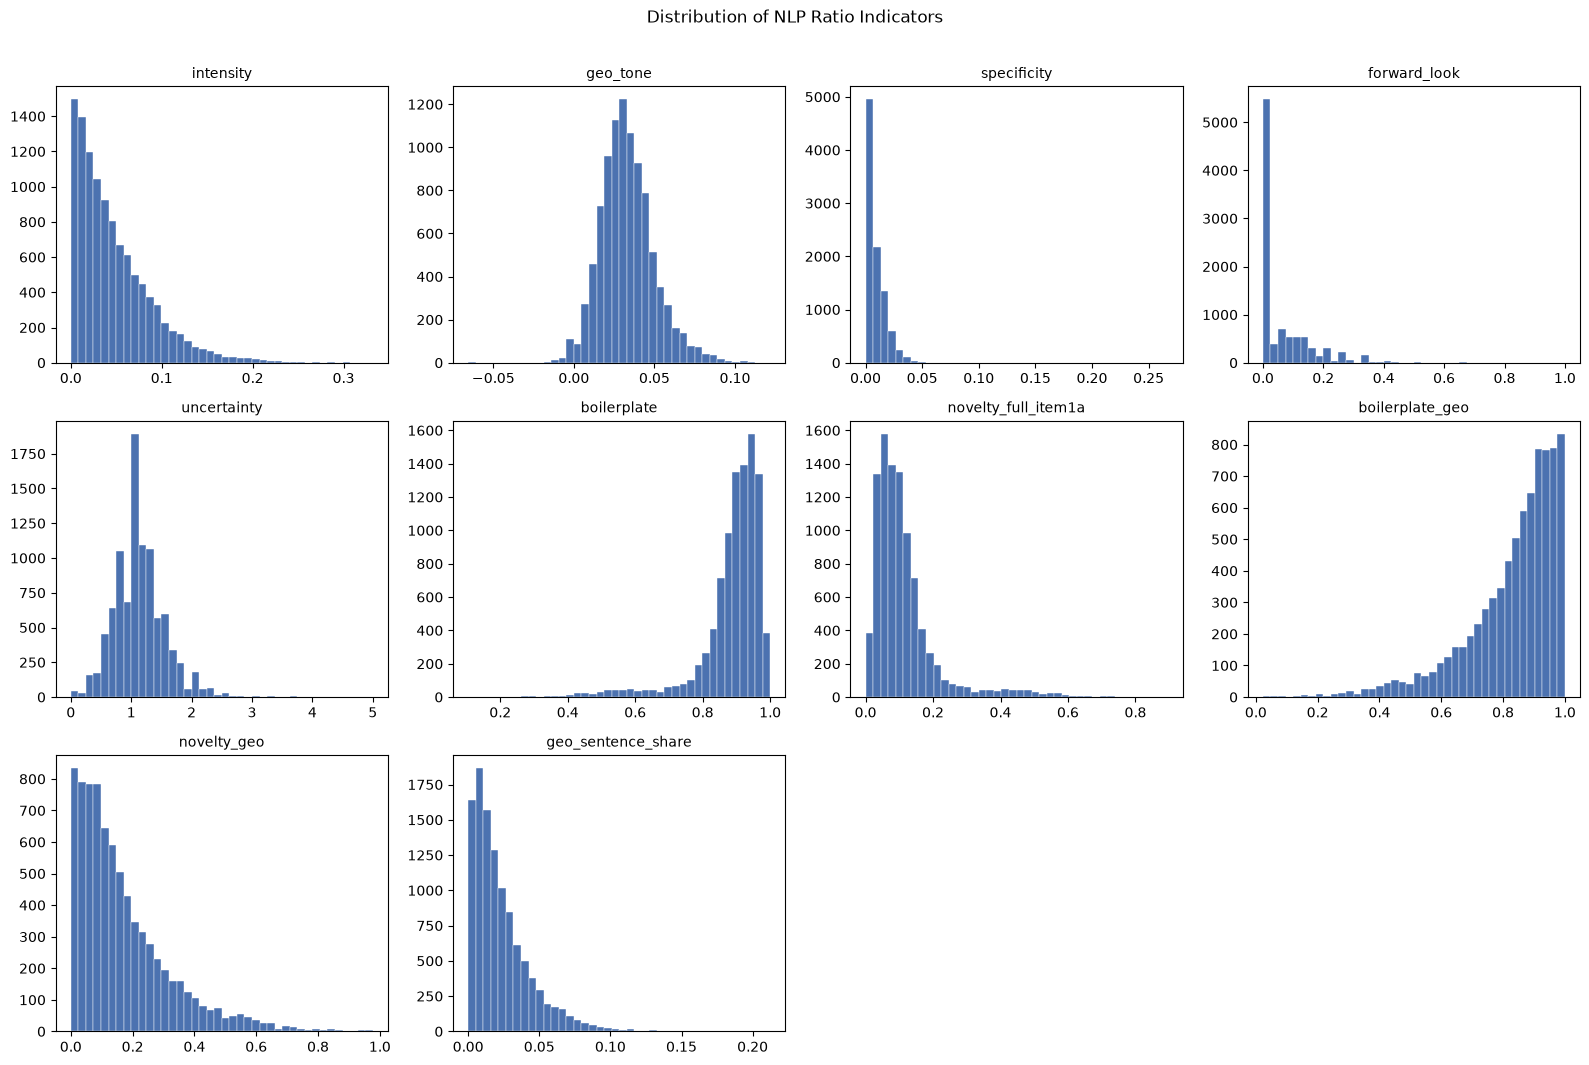

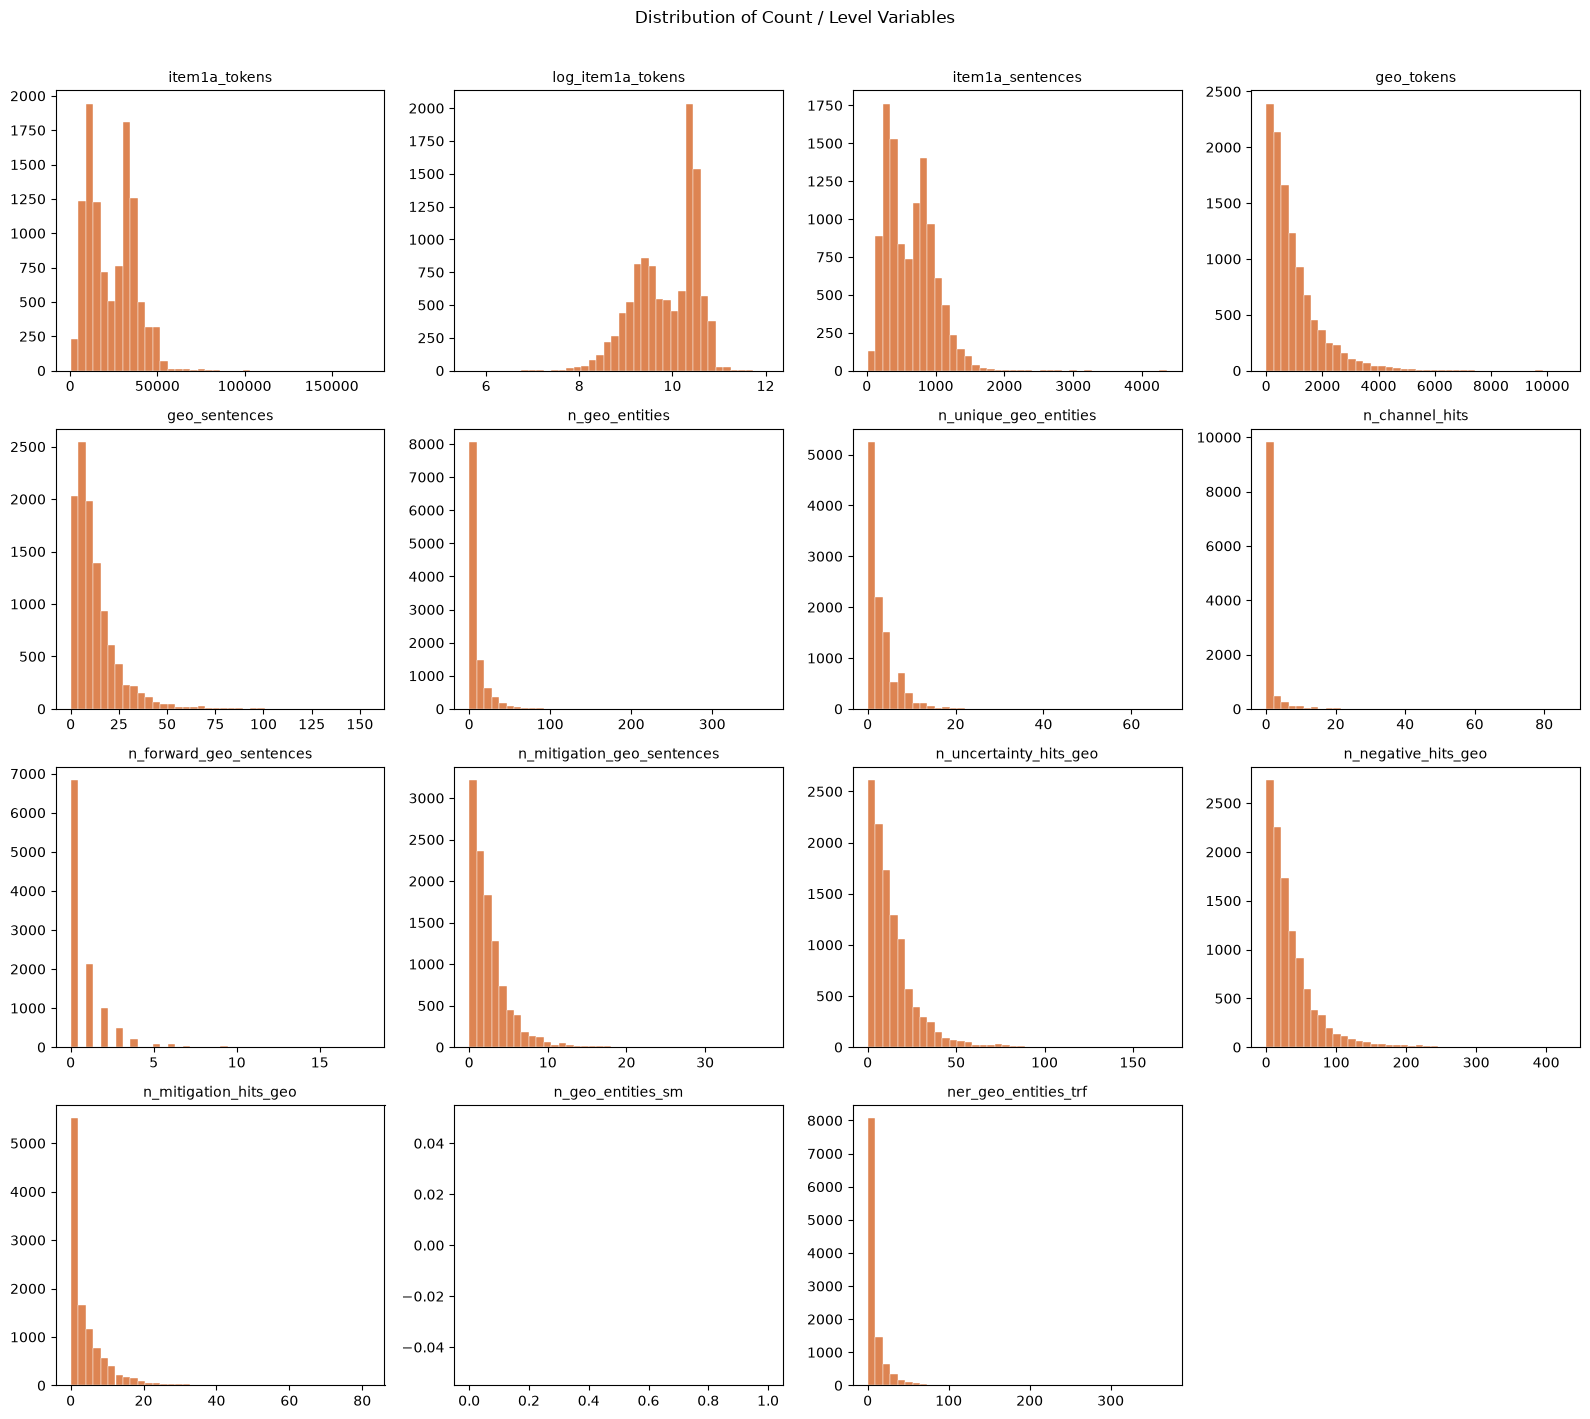

In [12]:
INDICATORS = [
    "intensity", "geo_tone", "specificity", "forward_look", "uncertainty",
    "boilerplate", "novelty_full_item1a",
    "boilerplate_geo", "novelty_geo",
]

# Dynamic: model-specific NER column (ner_geo_entities_trf, _lg, etc.)
_ner_model_cols = [c for c in df_feat.columns if c.startswith("ner_geo_entities_")]

COUNT_VARS = [
    "item1a_tokens", "log_item1a_tokens", "item1a_sentences",
    "geo_tokens", "geo_sentences",
    "n_geo_entities", "n_unique_geo_entities", "n_channel_hits",
    "n_forward_geo_sentences", "n_mitigation_geo_sentences",
    "n_uncertainty_hits_geo", "n_negative_hits_geo", "n_mitigation_hits_geo",
    "n_geo_entities_sm",
] + _ner_model_cols

ind_cols   = [c for c in INDICATORS  if c in df_feat.columns]
count_cols = [c for c in COUNT_VARS  if c in df_feat.columns]
meta_cols  = ["token_count", "sentence_count", "geo_sentence_count",
              "geo_sentence_share", "geo_token_count"]

# -- 1) Summary statistics — ratio indicators ----------------------------------
print("=== Ratio Indicator Summary Statistics ===")
display(df_feat[ind_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(4))

# -- 2) Summary statistics — count / level variables --------------------------
print("\n=== Count / Level Variable Summary Statistics ===")
display(df_feat[count_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))

# -- 3) NaN rates -------------------------------------------------------------
print("\n=== NaN rates (%) ===")
all_output_cols = ind_cols + count_cols + meta_cols
print((df_feat[[c for c in all_output_cols if c in df_feat.columns]]
       .isna().mean() * 100).round(1).to_string())

# -- 4) Correlation matrix — ratio indicators ---------------------------------
valid_ind = [c for c in ind_cols if df_feat[c].notna().any()]
corr = df_feat[valid_ind].corr().round(3)
print("\n=== Pairwise Correlations (Ratio Indicators) ===")
display(corr)

# -- 5) Distributions + heatmap -----------------------------------------------
if _HAS_PLOT:
    cols_to_plot = valid_ind + ["geo_sentence_share"]
    cols_to_plot = [c for c in cols_to_plot if c in df_feat.columns]
    ncols = 4
    nrows = -(-len(cols_to_plot) // ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
    for ax, col in zip(axes.flat, cols_to_plot):
        s = df_feat[col].dropna()
        ax.hist(s, bins=40, color="#4C72B0", edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
    for ax in axes.flat[len(cols_to_plot):]:
        ax.set_visible(False)
    plt.suptitle("Distribution of NLP Ratio Indicators", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()

    # Count variable distributions
    plot_counts = [c for c in count_cols if c in df_feat.columns]
    ncols2 = 4
    nrows2 = -(-len(plot_counts) // ncols2)
    fig3, axes3 = plt.subplots(nrows2, ncols2, figsize=(4 * ncols2, 3.5 * nrows2))
    for ax, col in zip(axes3.flat, plot_counts):
        s = df_feat[col].dropna()
        ax.hist(s, bins=40, color="#DD8452", edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
    for ax in axes3.flat[len(plot_counts):]:
        ax.set_visible(False)
    plt.suptitle("Distribution of Count / Level Variables", y=1.01, fontsize=12)
    plt.tight_layout()
    plt.show()

In [13]:
# Rows with extreme specificity (likely few geo tokens)
extreme = df_feat[df_feat["specificity"] > 0.10][
    ["company_name","fiscal_year","geo_token_count","geo_sentence_count","specificity"]
].sort_values("specificity", ascending=False)
display(extreme)

# Perfect boilerplate (full Item 1A)
display(df_feat[df_feat["boilerplate"] >= 0.999][
    ["company_name","fiscal_year","boilerplate","novelty_full_item1a","novelty_geo"]
])

# Forward look = 1.0 — check how many geo sentences they actually had
display(df_feat[df_feat["forward_look"] == 1.0][
    ["company_name","fiscal_year","geo_sentence_count","forward_look"]
].sort_values("geo_sentence_count"))

,company_name,fiscal_year,geo_token_count,geo_sentence_count,specificity
490,Cummins Inc,2021,1200,12,0.266667
492,Cummins Inc,2023,1487,14,0.236718
489,Cummins Inc,2020,1452,11,0.223829
493,Cummins Inc,2024,1779,17,0.207420
488,Cummins Inc,2019,1809,17,0.182421
491,Cummins Inc,2022,2097,25,0.163567
487,Cummins Inc,2018,1907,12,0.127950
494,Cummins Inc,2025,2845,39,0.127241
4364,Minerals Technologies Inc,2020,104,3,0.105769
4365,Minerals Technologies Inc,2021,105,3,0.104762


,company_name,fiscal_year,boilerplate,novelty_full_item1a,novelty_geo
346,Caterpillar Inc,2025,0.999732,0.000268,0.008954
1596,Mueller Industries,2023,1.000000,0.000000,NaN


,company_name,fiscal_year,geo_sentence_count,forward_look
3510,Pultegroup,2021,3,1.0
9429,Paylocity Holdings Corp,2020,3,1.0
9430,Paylocity Holdings Corp,2021,3,1.0


## 8 Feature checks, Table 4 and Table 5

In [14]:
# -- §8 Validation ────────────────────────────────────────────────────────
# All new columns that should be present in df_feat after the pipeline runs.

NEW_COLS = [
    # Text-length controls
    "item1a_tokens", "log_item1a_tokens", "item1a_sentences",
    # Geo count / level variables
    "geo_tokens", "geo_sentences",
    "n_geo_entities", "n_unique_geo_entities", "n_channel_hits",
    "n_forward_geo_sentences", "n_mitigation_geo_sentences",
    "n_uncertainty_hits_geo", "n_negative_hits_geo", "n_mitigation_hits_geo",
    # NER comparison
    "n_geo_entities_sm",
    # Novelty variants (primary + comparison)
    "novelty_full_item1a", "novelty_geo", "boilerplate_geo",
]
# Dynamic: model-specific NER column (name depends on which model loaded)
_ner_dyn = [c for c in df_feat.columns if c.startswith("ner_geo_entities_")]
NEW_COLS = NEW_COLS + _ner_dyn

# -- 1) Column presence check --------------------------------------------------
print("=== Column Presence Check ===")
missing = [c for c in NEW_COLS if c not in df_feat.columns]
present = [c for c in NEW_COLS if c in df_feat.columns]
print(f"  Present : {len(present)}/{len(NEW_COLS)}")
if missing:
    print(f"  MISSING : {missing}")
else:
    print("  All new columns present. \u2713")

# -- 2) Non-null coverage ------------------------------------------------------
print("\n=== Non-Null Coverage ===")
coverage = pd.DataFrame({
    "n_non_null": df_feat[present].notna().sum(),
    "n_total":    len(df_feat),
    "pct_non_null": (df_feat[present].notna().mean() * 100).round(1),
})
print(coverage.to_string())

# -- 3) Summary statistics for new variables -----------------------------------
print("\n=== Summary Statistics — New Variables ===")
# Exclude text columns (geo_text) from numeric summary
numeric_present = [c for c in present if df_feat[c].dtype != object]
display(df_feat[numeric_present].describe(percentiles=[.05, .25, .5, .75, .95]).round(2))

# -- 4) Sanity checks ----------------------------------------------------------
print("\n=== Sanity Checks ===")

if "item1a_tokens" in df_feat.columns and "token_count" in df_feat.columns:
    match = (df_feat["item1a_tokens"] == df_feat["token_count"]).all()
    print(f"  item1a_tokens == token_count              : {match}")

if "log_item1a_tokens" in df_feat.columns and "item1a_tokens" in df_feat.columns:
    match = np.allclose(df_feat["log_item1a_tokens"], np.log1p(df_feat["item1a_tokens"]))
    print(f"  log_item1a_tokens == log1p(item1a_tokens) : {match}")

if "geo_tokens" in df_feat.columns and "geo_token_count" in df_feat.columns:
    match = (df_feat["geo_tokens"] == df_feat["geo_token_count"]).all()
    print(f"  geo_tokens == geo_token_count             : {match}")

if "geo_sentences" in df_feat.columns and "geo_sentence_count" in df_feat.columns:
    match = (df_feat["geo_sentences"] == df_feat["geo_sentence_count"]).all()
    print(f"  geo_sentences == geo_sentence_count       : {match}")

if all(c in df_feat.columns for c in ["n_unique_geo_entities", "n_geo_entities"]):
    valid = (df_feat["n_unique_geo_entities"] <= df_feat["n_geo_entities"]).all()
    print(f"  n_unique_geo_entities <= n_geo_entities   : {valid}")

if all(c in df_feat.columns for c in ["novelty_geo", "novelty_full_item1a"]):
    n_geo = df_feat["novelty_geo"].notna().sum()
    n_full = df_feat["novelty_full_item1a"].notna().sum()
    print(f"  novelty_geo non-NaN                       : {n_geo}")
    print(f"  novelty_full_item1a non-NaN               : {n_full}")
    print(f"  novelty_geo <= novelty_full_item1a (obs)  : novelty_geo has fewer obs (expected)")

# Count vars: no negative values
neg_any = {c: int((df_feat[c] < 0).sum())
           for c in present
           if c in df_feat.columns and pd.api.types.is_numeric_dtype(df_feat[c])}
neg_cols = {k: v for k, v in neg_any.items() if v > 0}
if neg_cols:
    print(f"  WARNING — negative values found: {neg_cols}")
else:
    print("  No negative values in any numeric new column. \u2713")

=== Column Presence Check ===
  Present : 18/18
  All new columns present. ✓

=== Non-Null Coverage ===
                            n_non_null  n_total  pct_non_null
item1a_tokens                    10962    10962         100.0
log_item1a_tokens                10962    10962         100.0
item1a_sentences                 10962    10962         100.0
geo_tokens                       10962    10962         100.0
geo_sentences                    10962    10962         100.0
n_geo_entities                   10962    10962         100.0
n_unique_geo_entities            10962    10962         100.0
n_channel_hits                   10962    10962         100.0
n_forward_geo_sentences          10962    10962         100.0
n_mitigation_geo_sentences       10962    10962         100.0
n_uncertainty_hits_geo           10962    10962         100.0
n_negative_hits_geo              10962    10962         100.0
n_mitigation_hits_geo            10962    10962         100.0
n_geo_entities_sm           

,item1a_tokens,log_item1a_tokens,item1a_sentences,geo_tokens,geo_sentences,n_geo_entities,n_unique_geo_entities,n_channel_hits,n_forward_geo_sentences,n_mitigation_geo_sentences,n_uncertainty_hits_geo,n_negative_hits_geo,n_mitigation_hits_geo,n_geo_entities_sm,novelty_full_item1a,novelty_geo,boilerplate_geo,ner_geo_entities_trf
count,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,10962.00,0.0,9402.00,7860.00,7860.00,10962.00
mean,23751.35,9.88,633.00,958.20,12.62,8.30,2.86,0.92,0.76,2.23,13.69,34.55,4.47,NaN,0.11,0.17,0.83,8.30
std,13507.09,0.68,343.89,966.63,12.53,16.76,3.86,3.40,1.40,2.84,13.70,36.85,5.95,NaN,0.10,0.15,0.15,16.76
min,279.00,5.63,13.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,0.02,0.00
5%,6006.35,8.70,190.00,49.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,NaN,0.02,0.01,0.52,0.00
25%,11597.00,9.36,336.00,308.00,5.00,0.00,0.00,0.00,0.00,0.00,5.00,11.00,0.00,NaN,0.05,0.06,0.77,0.00
50%,22690.00,10.03,606.00,676.00,9.00,3.00,2.00,0.00,0.00,1.00,10.00,24.00,2.00,NaN,0.09,0.13,0.87,3.00
75%,33995.75,10.43,867.00,1283.00,16.00,10.00,4.00,0.00,1.00,3.00,18.00,46.00,6.00,NaN,0.13,0.23,0.94,10.00
95%,46253.55,10.74,1213.00,2816.90,35.00,33.00,9.00,5.00,3.00,7.00,39.00,103.00,16.00,NaN,0.32,0.48,0.99,33.00
max,171698.00,12.05,4357.00,10637.00,155.00,369.00,68.00,86.00,18.00,38.00,169.00,427.00,82.00,NaN,0.90,0.98,1.00,369.00



=== Sanity Checks ===
  item1a_tokens == token_count              : True
  log_item1a_tokens == log1p(item1a_tokens) : True
  geo_tokens == geo_token_count             : True
  geo_sentences == geo_sentence_count       : True
  n_unique_geo_entities <= n_geo_entities   : True
  novelty_geo non-NaN                       : 7860
  novelty_full_item1a non-NaN               : 9402
  novelty_geo <= novelty_full_item1a (obs)  : novelty_geo has fewer obs (expected)
  No negative values in any numeric new column. ✓


In [15]:
df_feat

,cik,company_name,fiscal_year,filing_date,report_date,accession_nodash,source_url,extract_version,token_count,sentence_count,...,uncertainty,n_uncertainty_hits_geo,gpr_category_dominant,gpr_category_shares,ner_geo_entities_trf,n_geo_entities_sm,boilerplate,novelty_full_item1a,boilerplate_geo,novelty_geo
0,1750,AAR Corp,2018,2018-07-11,2018-05-31,000104746918004978,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,3727,129,...,0.833333,5,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",1,NaN,NaN,NaN,NaN,NaN
1,1750,AAR Corp,2019,2019-07-18,2019-05-31,000104746919004266,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,4456,154,...,0.833333,5,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",1,NaN,0.904321,0.095679,0.994184,0.005816
2,1750,AAR Corp,2020,2020-07-21,2020-05-31,000110465920085310,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,15651,507,...,0.928571,13,conflict_terrorism,"{""conflict_terrorism"": 0.5, ""geopolitical_tens...",4,NaN,0.852693,0.147307,0.906571,0.093429
3,1750,AAR Corp,2021,2021-07-21,2021-05-31,000110465921094125,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,17385,556,...,0.941176,16,conflict_terrorism,"{""conflict_terrorism"": 0.5882, ""geopolitical_t...",3,NaN,0.881455,0.118545,0.912435,0.087565
4,1750,AAR Corp,2022,2022-07-21,2022-05-31,000110465922081498,https://www.sec.gov/Archives/edgar/data/1750/0...,v5_fixed,18122,577,...,1.045455,23,conflict_terrorism,"{""conflict_terrorism"": 0.5455, ""geopolitical_t...",16,NaN,0.877258,0.122742,0.841564,0.158436
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10957,2058873,Qnity Electronics Inc,2025,2026-02-26,2025-12-31,000205887326000010,https://www.sec.gov/Archives/edgar/data/205887...,v5_fixed,12715,297,...,1.727273,19,sanctions_trade,"{""conflict_terrorism"": 0.0909, ""geopolitical_t...",6,NaN,NaN,NaN,NaN,NaN
10958,2064953,Solstice Advanced Materials Inc,2025,2026-02-19,2025-12-31,000206495326000008,https://www.sec.gov/Archives/edgar/data/206495...,v5_fixed,27752,654,...,1.461538,38,sanctions_trade,"{""conflict_terrorism"": 0.1538, ""geopolitical_t...",18,NaN,NaN,NaN,NaN,NaN
10959,2067876,Versant Media Group Inc,2025,2026-03-03,2025-12-31,000206787626000010,https://www.sec.gov/Archives/edgar/data/206787...,v5_fixed,15505,367,...,NaN,3,geopolitical_tensions,"{""conflict_terrorism"": 0.0, ""geopolitical_tens...",0,NaN,NaN,NaN,NaN,NaN
10960,2074176,Viper Energy Inc,2025,2026-02-25,2025-12-31,000207417626000010,https://www.sec.gov/Archives/edgar/data/207417...,v5_fixed,10298,306,...,0.333333,1,sanctions_trade,"{""conflict_terrorism"": 0.0, ""geopolitical_tens...",0,NaN,NaN,NaN,NaN,NaN


In [4]:
df_feat = pd.read_parquet("../data/features/nlp_features.parquet")

def parse_cat_shares(s):
    try:
        return json.loads(s) if isinstance(s, str) else s
    except (json.JSONDecodeError, TypeError):
        return {}

cat_shares_expanded = df_feat["gpr_category_shares"].apply(parse_cat_shares).apply(pd.Series)

# ── 2. Map internal category keys → paper labels ─────────────────────────────
# Keys must match what _compute_category_breakdown() writes into the JSON.
CAT_MAP = {
    "conflict_terrorism":     "Cat 1: Conflict & Terror",
    "geopolitical_tensions":  "Cat 2: Interstate Tensions",
    "sanctions_trade":        "Cat 3: Sanctions & Trade",
    "regime_political":       "Cat 4: Regime Risk",
    "regulatory_sovereignty": "Cat 5: Reg. Sovereignty",
}

cat_shares_expanded = cat_shares_expanded.rename(columns=CAT_MAP)
cat_cols = list(CAT_MAP.values())

valid_mask = (
    (df_feat["geo_sentence_count"] >= MIN_GEO_SENTS) &
    (df_feat["geo_token_count"]    >= MIN_GEO_TOKENS)
)

df_for_table = pd.concat(
    [df_feat[["fiscal_year"]].reset_index(drop=True),
     cat_shares_expanded[cat_cols].reset_index(drop=True)],
    axis=1
)[valid_mask.values]

# ── 4. Compute annual cross-sectional means ───────────────────────────────────
table4_means = (
    df_for_table
    .groupby("fiscal_year")[cat_cols]
    .mean()
    .round(3)
)

# ── 5. Append N firms per year ───────────────────────────────────────────────
n_firms = (
    df_for_table
    .groupby("fiscal_year")
    .size()
    .rename("N firms")
)

table4 = table4_means.join(n_firms).reset_index()
table4 = table4.rename(columns={"fiscal_year": "Year"})

# ── 6. Display ───────────────────────────────────────────────────────────────
print("Table 4: Mean Geopolitical Risk Category Shares by Year")
print("(cross-sectional means; thin-denominator firm-years excluded)\n")
display(table4.set_index("Year"))


Table 4: Mean Geopolitical Risk Category Shares by Year
(cross-sectional means; thin-denominator firm-years excluded)



,Cat 1: Conflict & Terror,Cat 2: Interstate Tensions,Cat 3: Sanctions & Trade,Cat 4: Regime Risk,Cat 5: Reg. Sovereignty,N firms
Year,,,,,,
2018,0.431,0.062,0.443,0.173,0.026,921
2019,0.407,0.067,0.455,0.164,0.027,1048
2020,0.409,0.074,0.444,0.176,0.034,1081
2021,0.412,0.091,0.433,0.180,0.044,1162
2022,0.444,0.176,0.364,0.161,0.042,1248
2023,0.435,0.218,0.347,0.169,0.050,1292
2024,0.376,0.216,0.432,0.160,0.051,1347
2025,0.314,0.204,0.532,0.141,0.048,1390


In [5]:
# ── Table 5: category shares vs. Caldara-Iacoviello GPR index ────────────────
# Run directly after the Table 4 cell (uses df_feat, df_for_table, cat_cols).
import numpy as np
from scipy import stats

# 1. Annual GPR = calendar-year mean of the monthly index (same file as NB 07)
gpr = pd.read_excel("../data/validation/external/data_gpr_export.xls", sheet_name="Sheet1")
gpr["month"] = pd.to_datetime(gpr["month"])
gpr = gpr.drop_duplicates("month")
gpr = gpr[gpr["month"].dt.year.between(2018, 2025)]
year = gpr["month"].dt.year.rename("year")
n_months = gpr.groupby(year)["GPR"].count()
assert (n_months == 12).all(), f"Incomplete GPR years:\n{n_months[n_months != 12]}"
gpr_y = gpr.groupby(year)["GPR"].mean()

# 2. Annual category shares, UNROUNDED (non-thin filings, same sample as Table 4)
shares_y = df_for_table.groupby("fiscal_year")[cat_cols].mean()
years = sorted(set(shares_y.index) & set(gpr_y.index))
assert years == list(range(2018, 2026)), years
shares_y, gpr_y = shares_y.loc[years], gpr_y.loc[years]

# Intensity benchmark for 3.5.2 / Figure 1 (all filings), used as a sanity check below
int_y = df_feat.groupby("fiscal_year")["intensity"].mean().loc[years]


def detrend(s):
    """Residuals after removing a linear time trend."""
    v = np.asarray(s, dtype=float)
    t = np.arange(len(v))
    return v - np.polyval(np.polyfit(t, v, 1), t)


def corr_row(x, y=gpr_y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    r, p = stats.pearsonr(x, y)
    rho, p_rho = stats.spearmanr(x, y)
    r_chg, p_chg = stats.pearsonr(np.diff(x), np.diff(y))
    r_dt, p_dt = stats.pearsonr(detrend(x), detrend(y))
    return {"Pearson r": r, "p-value": p, "Spearman rho": rho, "p-value (rho)": p_rho,
            "r (changes)": r_chg, "p (changes)": p_chg, "r (detrended)": r_dt, "p (detrended)": p_dt}


table5 = pd.DataFrame({c: corr_row(shares_y[c]) for c in cat_cols}).T
table5.insert(0, "Mean share", shares_y.mean())   # average of the 8 annual means, as in Table 5

# 3. Output
print("Annual GPR index (calendar-year mean of the monthly index):")
print(gpr_y.round(3).to_string())
print("\nTable 5: Category-level correlations with the GPR index, 2018-2025 (n = 8 years)")
display(table5[["Mean share", "Pearson r", "p-value", "Spearman rho", "p-value (rho)"]].round(3))
print("\nFor the text: year-to-year changes (n = 7) and linearly detrended series (n = 8)")
display(table5[["r (changes)", "p (changes)", "r (detrended)", "p (detrended)"]].round(3))
print("\nSanity check, mean intensity vs GPR (draft 3.5.2: r = 0.83, rho = 0.69, changes 0.87, detrended 0.78):")
print(pd.Series(corr_row(int_y)).round(3).to_string())

Annual GPR index (calendar-year mean of the monthly index):
year
2018     98.553
2019     90.946
2020     77.294
2021     82.070
2022    157.583
2023    121.711
2024    134.453
2025    145.079

Table 5: Category-level correlations with the GPR index, 2018-2025 (n = 8 years)


,Mean share,Pearson r,p-value,Spearman rho,p-value (rho)
Cat 1: Conflict & Terror,0.403,-0.258,0.537,0.071,0.867
Cat 2: Interstate Tensions,0.138,0.830,0.011,0.548,0.160
Cat 3: Sanctions & Trade,0.431,-0.136,0.748,-0.286,0.493
Cat 4: Regime Risk,0.166,-0.761,0.028,-0.833,0.010
Cat 5: Reg. Sovereignty,0.040,0.586,0.127,0.429,0.289



For the text: year-to-year changes (n = 7) and linearly detrended series (n = 8)


,r (changes),p (changes),r (detrended),p (detrended)
Cat 1: Conflict & Terror,0.314,0.493,0.312,0.452
Cat 2: Interstate Tensions,0.542,0.209,0.621,0.100
Cat 3: Sanctions & Trade,-0.240,0.604,-0.279,0.504
Cat 4: Regime Risk,-0.726,0.065,-0.529,0.178
Cat 5: Reg. Sovereignty,-0.619,0.139,-0.322,0.437



Sanity check, mean intensity vs GPR (draft 3.5.2: r = 0.83, rho = 0.69, changes 0.87, detrended 0.78):
Pearson r        0.832
p-value          0.010
Spearman rho     0.690
p-value (rho)    0.058
r (changes)      0.873
p (changes)      0.010
r (detrended)    0.784
p (detrended)    0.021


In [17]:
df_feat['log_item1a_tokens']

0         8.223627
1         8.402231
2         9.658354
3         9.763421
4         9.804937
           ...    
10957     9.450616
10958    10.231099
10959     9.648982
10960     9.239802
10961    10.096007
Name: log_item1a_tokens, Length: 10962, dtype: float64

## 9 Novelty placebo and non-geopolitical novelty

The second cell (five draws) writes the `novelty_placebo.csv` used in 06.

In [9]:
import hashlib

feat = pd.read_parquet(OUT_PARQUET, columns=["cik", "fiscal_year", "geo_text", "geo_sentence_count",
                                             "geo_token_count", "novelty_geo", "novelty_full_item1a"])
base = df_raw[["cik", "fiscal_year", "item_1a_text"]].merge(
    feat, on=["cik", "fiscal_year"], how="left", validate="1:1")
thin = (base["geo_sentence_count"] < MIN_GEO_SENTS) | (base["geo_token_count"] < MIN_GEO_TOKENS)

def _sent_key(s: str) -> str:
    return hashlib.md5(_WS.sub(" ", s.lower()).strip().encode("utf-8")).hexdigest()

def placebo_text(item_text, geo_text, target_tokens):
    sents   = split_sentences(clean_text(str(item_text)))
    geo_set = set(split_sentences(clean_text(geo_text))) if isinstance(geo_text, str) and geo_text else set()
    non_geo = sorted({s for s in sents if s not in geo_set}, key=_sent_key)
    out, n = [], 0
    for s in non_geo:
        if n >= target_tokens:
            break
        out.append(s)
        n += len(tokenize(s))
    return " ".join(out), n, sum(s in geo_set for s in sents)

res = [("", 0, 0) if th else placebo_text(t, g, int(n))
       for t, g, n, th in zip(base["item_1a_text"], base["geo_text"],
                              base["geo_token_count"].fillna(0), thin)]
base["placebo_text"]   = [r[0] for r in res]
base["placebo_tokens"] = [r[1] for r in res]
base["n_geo_removed"]  = [r[2] for r in res]

ok = ~thin
print(f"Geo sentences recovered exactly : "
      f"{(base.loc[ok, 'n_geo_removed'] == base.loc[ok, 'geo_sentence_count']).mean():.1%} of non-thin filings")
print(f"Placebo < 90% of geo size       : "
      f"{(base.loc[ok, 'placebo_tokens'] < 0.9 * base.loc[ok, 'geo_token_count']).mean():.1%}")

bp_pl = compute_boilerplate(base, text_col="placebo_text")
base["novelty_placebo"] = bp_pl["novelty"].clip(lower=0).values

out = base[["cik", "fiscal_year", "novelty_placebo", "placebo_tokens", "n_geo_removed"]]
out.to_csv("../data/features/novelty_placebo.csv", index=False)
print(base[["novelty_geo", "novelty_full_item1a", "novelty_placebo"]].describe().round(3))
print(base[["novelty_geo", "novelty_full_item1a", "novelty_placebo"]].corr().round(3))

Geo sentences recovered exactly : 100.0% of non-thin filings
Placebo < 90% of geo size       : 0.0%
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
       novelty_geo  novelty_full_item1a  novelty_placebo
count     7860.000             9402.000         7860.000
mean         0.168                0.114            0.469
std          0.150                0.101            0.201
min          0.000                0.000            0.000
25%          0.059                0.053            0.315
50%          0.125                0.090            0.451
75%          0.234                0.135            0.612
max          0.977                0.895            0.989
                     novelty_geo  novelty_full_item1a  novelty_placebo
novelty_geo                1.000                0.351            0.322
novelty_full_item1a        0.351                1.000            0.548
novelty_placebo            0.322                0.548            1.000


In [13]:
import hashlib, warnings

K_DRAWS = 5      # independent size-matched draws, averaged

feat = pd.read_parquet(OUT_PARQUET, columns=["cik", "fiscal_year", "geo_text", "geo_sentence_count",
                                             "geo_token_count", "novelty_geo", "novelty_full_item1a"])
base = df_raw[["cik", "fiscal_year", "item_1a_text"]].merge(
    feat, on=["cik", "fiscal_year"], how="left", validate="1:1")
thin = (base["geo_sentence_count"] < MIN_GEO_SENTS) | (base["geo_token_count"] < MIN_GEO_TOKENS)

_NONALPHA = re.compile(r"[^a-z ]+")
def _norm(s):
    """Selection key: lower case, letters only. Updated years/numbers do not change the key."""
    return _WS.sub(" ", _NONALPHA.sub(" ", s.lower())).strip()

def _split_geo(item_text, geo_text):
    sents   = split_sentences(clean_text(str(item_text)))
    geo_set = set(split_sentences(clean_text(geo_text))) if isinstance(geo_text, str) and geo_text else set()
    non_geo, seen = [], set()
    for s in sents:
        if s in geo_set:
            continue
        k = _norm(s)
        if k and k not in seen:
            seen.add(k)
            non_geo.append((k, s, len(tokenize(s))))
    return non_geo, sum(s in geo_set for s in sents)

def _pick(non_geo, target, seed):
    order = sorted(non_geo, key=lambda x: hashlib.md5(f"{seed}|{x[0]}".encode("utf-8")).hexdigest())
    out, n = [], 0
    for _, s, nt in order:
        if n >= target:
            break
        out.append(s)
        n += nt
    return " ".join(out), n

split = [([], 0) if th else _split_geo(t, g)
         for t, g, th in zip(base["item_1a_text"], base["geo_text"], thin)]
base = base.drop(columns=["item_1a_text"])            # free memory
base["n_geo_removed"] = [s[1] for s in split]
ok = ~thin
print(f"Geo sentences recovered exactly : "
      f"{(base.loc[ok, 'n_geo_removed'] == base.loc[ok, 'geo_sentence_count']).mean():.1%} of non-thin filings")

# (a) All non-geopolitical text: general rewriting, no size matching, no selection noise
base["nongeo_text"] = [" ".join(x[1] for x in s[0]) for s in split]
base["novelty_nongeo"] = compute_boilerplate(base, text_col="nongeo_text")["novelty"].clip(lower=0).values
base = base.drop(columns=["nongeo_text"])

# (b) Size-matched placebo: K draws with different hash seeds, averaged
draws, short = [], []
for seed in range(K_DRAWS):
    picked = [("", 0) if th else _pick(s[0], int(n), seed)
              for s, n, th in zip(split, base["geo_token_count"].fillna(0), thin)]
    base["placebo_text"] = [p[0] for p in picked]
    short.append(np.mean([p[1] < 0.9 * n for p, n, th in zip(picked, base["geo_token_count"], thin) if not th]))
    draws.append(compute_boilerplate(base, text_col="placebo_text")["novelty"].clip(lower=0).values)
D = np.vstack(draws)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    base["novelty_placebo"]    = np.nanmean(D, axis=0)
    base["novelty_placebo_sd"] = np.nanstd(D, axis=0)
print(f"Placebo < 90% of geo size (mean over draws): {np.mean(short):.1%}")

out = base[["cik", "fiscal_year", "novelty_placebo", "novelty_placebo_sd", "novelty_nongeo", "n_geo_removed"]]
out.to_csv("../data/features/novelty_placebo.csv", index=False)
cols = ["novelty_geo", "novelty_full_item1a", "novelty_nongeo", "novelty_placebo"]
print(base[cols + ["novelty_placebo_sd"]].describe().round(3))
print(base[cols].corr().round(3))

Geo sentences recovered exactly : 100.0% of non-thin filings
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
[boilerplate] 7860/10962 firm-years have a valid prior-year match.
Placebo < 90% of geo size (mean over draws): 0.0%
       novelty_geo  novelty_full_item1a  novelty_nongeo  novelty_placebo  \
count     7860.000             9402.000        7860.000         7860.000   
mean         0.168                0.114           0.109            0.435   
std          0.150                0.101           0.093            0.165   
min          0.000                0.000           0.000            0.000   
25%          0.059                0.053           0.051            0.311   
50%          0.125             

## 10 LLM validation sample

600 sentences (300 / 200 / 100 by stratum) from 300 filings; prompt in `prompts/validation_prompt_v2.md`, rater returns in `output/validation/v2/returns/`. Produces Appendices VIII and IX.

In [10]:
VAL_DIR = Path("../output/validation/v2")
(VAL_DIR / "packets").mkdir(parents=True, exist_ok=True)
(VAL_DIR / "returns").mkdir(parents=True, exist_ok=True)

frame = df_raw.sample(n=300, random_state=42)[["cik", "fiscal_year", "item_1a_text"]]
BROAD = re.compile(
    r"\b(geopolit\w*|sanction\w*|tariff\w*|trade (war|dispute|polic\w*|tension\w*|restriction\w*)|"
    r"export control\w*|embargo\w*|wars?|conflicts?|military|terror\w*|unrest|instability|"
    r"political\w*|international|foreign|countr(y|ies)|china|chinese|russia\w*|ukrain\w*|israel\w*|"
    r"middle east|taiwan|iran\w*|north korea|europe\w*|brexit|nationali[sz]\w*|expropriat\w*|decoupling)\b",
    re.I)

rows = []
for r in frame.itertuples():
    sents = split_sentences(clean_text(str(r.item_1a_text)))
    for k, s in enumerate(sents):
        flag = bool(is_gpr_sentence(s))
        rows.append({"cik": r.cik, "fiscal_year": r.fiscal_year, "pos": k, "sentence": s,
                     "context_before": sents[k - 1] if k else "", "pipeline_geo": int(flag),
                     "stratum": "A_flagged" if flag else ("B_candidate" if BROAD.search(s) else "C_other")})
pool = pd.DataFrame(rows)
pool = pool[pool["sentence"].str.split().str.len().between(6, 120)]
pop = pool["stratum"].value_counts()
print("Frame sizes:\n", pop.to_string())

N_SAMPLE = {"A_flagged": 300, "B_candidate": 200, "C_other": 100}
samp = pd.concat([pool[pool["stratum"] == s].sample(n=min(n, pop[s]), random_state=42)
                  for s, n in N_SAMPLE.items()])
samp["weight"] = samp["stratum"].map(pop) / samp["stratum"].map(samp["stratum"].value_counts())

# Pipeline sentence-level components (same functions as the indicators; trf NER for specificity)
nlp_trf, short = _load_spacy()
assert short == "trf"
def components(s):
    g = classify_geo_sentences(s)
    if not g["geo_sents"]:
        return {k: np.nan for k in ["p_negative", "p_mitigation", "p_forward", "p_hedged", "p_specific"]}
    t, f = compute_geo_tone(g), compute_forward_look(g)
    u, sp = compute_uncertainty(g), compute_specificity(g, nlp=nlp_trf)
    return {"p_negative":   int(t["n_negative_hits_geo"] > 0),
            "p_mitigation": int(t["n_mitigation_hits_geo"] > 0),
            "p_forward":    int(f["n_forward_geo_sentences"] > 0),
            "p_hedged":     int(u["n_uncertainty_hits_geo"] > 0),
            "p_specific":   int((sp["n_geo_entities"] + sp["n_channel_hits"]) > 0)}
samp = pd.concat([samp.reset_index(drop=True),
                  pd.DataFrame([components(s) for s in samp["sentence"]])], axis=1)

samp = samp.sample(frac=1, random_state=7).reset_index(drop=True)
samp["sid"] = [f"s{i + 1:04d}" for i in range(len(samp))]
samp.to_csv(VAL_DIR / "manifest_HIDDEN.csv", index=False)     # never give this file to raters

prompt = Path("../prompts/validation_prompt_v2.md").read_text(encoding="utf-8")
PACKET = 50
for j in range(0, len(samp), PACKET):
    body = "\n\n".join(
        f"### {r.sid}\nContext (previous sentence): {(r.context_before or '-')[:400]}\nSENTENCE: {r.sentence}"
        for r in samp.iloc[j:j + PACKET].itertuples())
    (VAL_DIR / "packets" / f"packet_{j // PACKET + 1:02d}.md").write_text(
        prompt + "\n\n---\n\n" + body, encoding="utf-8")
print(f"{len(samp)} sentences in {int(np.ceil(len(samp) / PACKET))} packets ->", VAL_DIR / "packets")
print(samp["stratum"].value_counts().to_string())

Frame sizes:
 stratum
C_other        163550
B_candidate      9867
A_flagged        3361


NameError: name '_load_spacy' is not defined

In [10]:
import io
from itertools import combinations
from sklearn.metrics import cohen_kappa_score

VAL_DIR = Path("../output/validation/v2")
LABELS  = ["geo", "negative", "mitigation", "forward", "hedged", "specific"]
man = pd.read_csv(VAL_DIR / "manifest_HIDDEN.csv").set_index("sid")

def load_rater(path):
    """Handles Excel-style exports (BOM, each line wrapped in quotes). Enforces the prompt rule
    that all content labels are 0 when geo = 0."""
    lines = [l.strip().strip('"') for l in open(path, encoding="utf-8-sig").read().splitlines() if l.strip()]
    r = pd.read_csv(io.StringIO("\n".join(lines)))
    r.columns = r.columns.str.strip().str.lower()
    r = r.drop_duplicates("sid").set_index("sid")[LABELS].astype(int)
    n_viol = int(((r["geo"] == 0) & (r[LABELS[1:]].sum(axis=1) > 0)).sum())
    r.loc[r["geo"] == 0, LABELS[1:]] = 0
    return r, n_viol

raters = {}
for f in sorted((VAL_DIR / "returns").glob("*.csv")):
    name = f.stem.replace("_output", "")
    raters[name], nv = load_rater(f)
    print(f"{name:<11s} n={len(raters[name])}  missing={len(man.index.difference(raters[name].index))}  "
          f"geo=0 rule violations fixed: {nv}")

# 1. Pairwise inter-rater agreement (content labels only where both raters say geo = 1)
irr = []
for a, b in combinations(raters, 2):
    c = raters[a].index.intersection(raters[b].index)
    for lab in LABELS:
        idx = c if lab == "geo" else c[(raters[a].loc[c, "geo"] == 1) & (raters[b].loc[c, "geo"] == 1)]
        irr.append({"pair": f"{a}-{b}", "label": lab, "n": len(idx),
                    "kappa": cohen_kappa_score(raters[a].loc[idx, lab], raters[b].loc[idx, lab]),
                    "agreement": (raters[a].loc[idx, lab] == raters[b].loc[idx, lab]).mean()})
irr = pd.DataFrame(irr)
print(irr.pivot(index="label", columns="pair", values="kappa").round(2).to_string())

# 2. Majority consensus (2 of 3; with 2 raters available both must agree; ties -> missing)
stack = pd.concat(raters, axis=1)
cons = pd.DataFrame(index=man.index)
for lab in LABELS:
    v = stack.xs(lab, axis=1, level=1).reindex(man.index)
    k, s = v.notna().sum(axis=1), v.sum(axis=1)
    cons[lab] = np.where(s * 2 > k, 1, np.where(s * 2 < k, 0, np.nan))
cons.loc[cons["geo"] == 0, LABELS[1:]] = 0
print(f"\nconsensus ties on geo (dropped): {int(cons['geo'].isna().sum())}")

# 3. Classifier precision / recall (stratum-weighted) with stratified bootstrap CIs
def prf(df, strata=None):
    d = df if strata is None else df[df["stratum"].isin(strata)]
    w, y, p = d["weight"], d["truth"], d["pipeline_geo"]
    tp = (w * ((p == 1) & (y == 1))).sum(); fp = (w * ((p == 1) & (y == 0))).sum()
    fn = (w * ((p == 0) & (y == 1))).sum()
    return (tp / (tp + fp) if tp + fp else np.nan), (tp / (tp + fn) if tp + fn else np.nan)

def boot(df, strata=None, B=2000, seed=1):
    rng = np.random.default_rng(seed); groups = [g for _, g in df.groupby("stratum")]; vals = []
    for _ in range(B):
        s = pd.concat([g.sample(len(g), replace=True, random_state=int(rng.integers(1e9))) for g in groups])
        vals.append(prf(s, strata))
    return np.nanpercentile(np.array(vals), [2.5, 97.5], axis=0)

rows = []
for name, truth in [("majority", cons["geo"])] + [(n, r["geo"]) for n, r in raters.items()]:
    d = man.join(truth.rename("truth"), how="inner").dropna(subset=["truth"])
    for scope, strata in [("all strata", None), ("A+B (candidate space)", ["A_flagged", "B_candidate"])]:
        p, r_ = prf(d, strata); lo, hi = boot(d, strata)
        rows.append({"truth": name, "scope": scope, "n": len(d), "precision": p,
                     "prec_ci": f"[{lo[0]:.2f}, {hi[0]:.2f}]", "recall": r_, "rec_ci": f"[{lo[1]:.2f}, {hi[1]:.2f}]",
                     **{f"geo_rate_{s}": d.loc[d["stratum"] == s, "truth"].mean()
                        for s in ["A_flagged", "B_candidate", "C_other"]}})
clf = pd.DataFrame(rows)
print(clf.round(3).to_string(index=False))

# 4. Component validity: pipeline-flagged sentences the majority also calls geopolitical
cmap = {"negative": "p_negative", "mitigation": "p_mitigation", "forward": "p_forward",
        "hedged": "p_hedged", "specific": "p_specific"}
sub = man[man["pipeline_geo"] == 1].join(cons, how="inner")
sub = sub[sub["geo"] == 1]
comp = []
for lab, pc in cmap.items():
    s = sub.dropna(subset=[lab, pc])
    comp.append({"component": lab, "n": len(s), "accuracy": (s[lab] == s[pc]).mean(),
                 "kappa": cohen_kappa_score(s[lab].astype(int), s[pc].astype(int)),
                 "pipeline_rate": s[pc].mean(), "rater_rate": s[lab].mean()})
comp = pd.DataFrame(comp)
print(comp.round(3).to_string(index=False))

# 5. Error lists
err = man.join(cons[["geo"]].rename(columns={"geo": "majority_geo"}), how="left")
err[(err["pipeline_geo"] == 1) & (err["majority_geo"] == 0)][["stratum", "sentence"]].to_csv(VAL_DIR / "false_positives.csv")
err[(err["pipeline_geo"] == 0) & (err["majority_geo"] == 1)][["stratum", "sentence"]].to_csv(VAL_DIR / "false_negatives.csv")
irr.to_csv(VAL_DIR / "interrater_kappa.csv", index=False)
clf.to_csv(VAL_DIR / "classifier_validation.csv", index=False)
comp.to_csv(VAL_DIR / "component_validation.csv", index=False)
cons.to_csv(VAL_DIR / "consensus_labels.csv")

claude      n=600  missing=0  geo=0 rule violations fixed: 0
gemini      n=600  missing=0  geo=0 rule violations fixed: 151
GPT         n=600  missing=0  geo=0 rule violations fixed: 1
pair        claude-GPT  claude-gemini  gemini-GPT
label                                            
forward           0.67           0.44        0.41
geo               0.87           0.82        0.82
hedged            0.78           0.58        0.57
mitigation        0.68           0.65        0.60
negative          0.57           0.53        0.41
specific          0.63           0.69        0.62

consensus ties on geo (dropped): 0
   truth                 scope   n  precision      prec_ci  recall       rec_ci  geo_rate_A_flagged  geo_rate_B_candidate  geo_rate_C_other
majority            all strata 600      0.840 [0.80, 0.88]   0.317 [0.18, 0.70]               0.840                 0.120              0.03
majority A+B (candidate space) 600      0.840 [0.80, 0.88]   0.705 [0.63, 0.79]               0.840